STEP 1: Loading full cisTopic object for MG cell barcodes


/home/jacwe/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


MG cells found: 1977

STEP 2: Loading ATAC matrix and filtering to MG cells
Raw matrix: 119,515 peaks × 18,959 cells
MG cells found in matrix: 1977
Peaks after MG filter (min_cells=19): 109,750 of 119,515
Region name sample: [':1:33501-34428', ':1:38097-38997', ':1:50233-51020']

STEP 4: Building MG-only CistopicObject
CistopicObject from project MG_only with n_cells × n_regions = 1977 × 109750
Cells:   1977
Regions: 109750

STEP 5: Running LDA topic models


2026-04-13 15:16:32,307	INFO worker.py:1715 -- Started a local Ray instance. View the dashboard at http://127.0.0.1:8265 
(pid=17972) /home/jacwe/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
(pid=17972)   from pkg_resources import DistributionNotFound, get_distribution


(run_cgs_model pid=17972) 2026-04-13 15:16:33,248 cisTopic     INFO     Running model with 4 topics
(run_cgs_model pid=17972) 2026-04-13 15:18:04,951 cisTopic     INFO     Model with 4 topics done!
(run_cgs_model pid=17972) 2026-04-13 15:18:04,968 cisTopic     INFO     Running model with 5 topics
(run_cgs_model pid=17972) 2026-04-13 15:19:45,591 cisTopic     INFO     Model with 5 topics done!
(run_cgs_model pid=17972) 2026-04-13 15:19:45,607 cisTopic     INFO     Running model with 6 topics
(run_cgs_model pid=17972) 2026-04-13 15:21:33,391 cisTopic     INFO     Model with 6 topics done!
(run_cgs_model pid=17972) 2026-04-13 15:21:33,407 cisTopic     INFO     Running model with 7 topics
(run_cgs_model pid=17972) 2026-04-13 15:23:30,792 cisTopic     INFO     Model with 7 topics done!
(run_cgs_model pid=17972) 2026-04-13 15:23:30,808 cisTopic     INFO     Running model with 8 topics
(run_cgs_model pid=17972) 2026-04-13 15:25:36,162 cisTopic     INFO     Model with 8 topics done!

Models tr

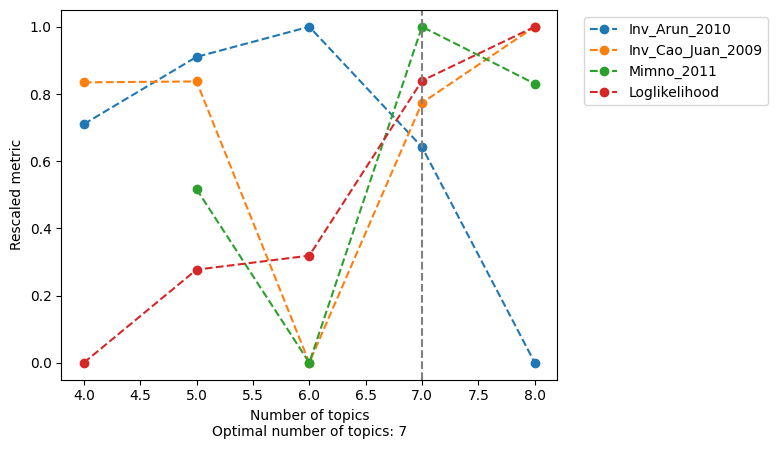

Saved evaluation PDF: scenicplus_input/MG_cistopic_model_evaluation.pdf
Selected: 5 topics  coherence=1.0719

Saved: scenicplus_input/atac_cistopic_mg_only.pkl

STEP 8: Binarizing topics (Otsu)
Topics binarized: 5
  Topic1: 5,883 regions
  Topic2: 2,674 regions
  Topic3: 4,770 regions
  Topic4: 8,813 regions
  Topic5: 2,755 regions

STEP 9: Exporting BED files
  wrote: Topic1.bed (5,883 regions)
  wrote: Topic2.bed (2,674 regions)
  wrote: Topic3.bed (4,770 regions)
  wrote: Topic4.bed (8,813 regions)
  wrote: Topic5.bed (2,755 regions)

Wrote 5 BED files to scenicplus_input/region_sets_mg/Topics_MG


<Figure size 640x480 with 0 Axes>

In [1]:
#!/usr/bin/env python3
"""
01_preprocess_rna_atac_MG.py
============================
MG-only version — generates:
  - scenicplus_input/atac_cistopic_mg_only.pkl
  - scenicplus_input/region_sets_mg_topics_otsu.pkl
  - scenicplus_input/region_sets_mg/Topics_MG/*.bed

All RNA preprocessing unchanged — RNA h5ad already exists.
"""

import os, json, warnings, pickle, gc, random, re
import numpy as np
import pandas as pd
from scipy.io import mmread
from scipy.sparse import csr_matrix
from pathlib import Path

INDIR = Path("scenicplus_input")

# ── CONFIG ────────────────────────────────────────────────────────
OUT_CISTOPIC_MG_PKL  = INDIR / "atac_cistopic_mg_only.pkl"
OUT_BIN_TOPICS_MG    = INDIR / "region_sets_mg_topics_otsu.pkl"
REGION_SETS_MG_DIR   = INDIR / "region_sets_mg"
TOPICS_MG_DIR        = REGION_SETS_MG_DIR / "Topics_MG"

MG_CELL_TYPES        = ["activated MG", "resting MG"]
MIN_CELLS_PER_PEAK   = 0.01   # fraction of MG cells
TOPICS_TO_TRY        = [4, 5, 6, 7, 8]
N_ITER               = 150
RANDOM_STATE         = 555
N_CPU                = 1

# ============================================================
# STEP 1 — Load existing cisTopic object to get MG barcodes
# ============================================================
print("=" * 60)
print("STEP 1: Loading full cisTopic object for MG cell barcodes")
print("=" * 60)

with open(INDIR / "atac_cistopic_selected_model_chrstr.pkl", "rb") as f:
    cistopic_full = pickle.load(f)

cell_data = cistopic_full.cell_data
mg_cells  = cell_data[cell_data["celltype"].isin(MG_CELL_TYPES)].index.tolist()
print(f"MG cells found: {len(mg_cells)}")
del cistopic_full
gc.collect()

# ============================================================
# STEP 2 — Load raw ATAC matrix + filter to MG cells
# ============================================================
print("\n" + "=" * 60)
print("STEP 2: Loading ATAC matrix and filtering to MG cells")
print("=" * 60)

A          = mmread(INDIR / "atac_matrix.mtx").tocsr()   # peaks × cells
atac_cells = pd.read_csv(INDIR / "atac_barcodes.tsv", sep="\t", header=None).iloc[:, 0].astype(str).tolist()
peaks_df   = pd.read_csv(INDIR / "peaks.bed", sep="\t", header=None, names=["chr", "start", "end"])

print(f"Raw matrix: {A.shape[0]:,} peaks × {A.shape[1]:,} cells")

# Build region names in :chrom:start-end format
chrom        = peaks_df["chr"].astype(str).str.replace(r"^chr", "", regex=True)
region_names = (
    ":" + chrom + ":" +
    peaks_df["start"].astype(int).astype(str) + "-" +
    peaks_df["end"].astype(int).astype(str)
).tolist()

# Subset to MG cells
cell_to_col = {c: i for i, c in enumerate(atac_cells)}
mg_idx      = [cell_to_col[c] for c in mg_cells if c in cell_to_col]
print(f"MG cells found in matrix: {len(mg_idx)}")

A_mg = A[:, mg_idx]  # peaks × MG cells
mg_barcodes_used = [mg_cells[i] for i, c in enumerate(mg_cells) if c in cell_to_col]

# Filter peaks — keep only those accessible in ≥1% of MG cells
peak_counts = np.asarray((A_mg > 0).sum(axis=1)).ravel()
min_cells   = max(5, int(len(mg_idx) * MIN_CELLS_PER_PEAK))
keep        = peak_counts >= min_cells

A_mg         = A_mg[keep, :]
binary_A_mg  = (A_mg > 0).astype("int32").tocsr()
region_names = [r for r, k in zip(region_names, keep) if k]
peaks_df_mg  = peaks_df.loc[keep].reset_index(drop=True)

print(f"Peaks after MG filter (min_cells={min_cells}): {A_mg.shape[0]:,} of {len(keep):,}")
print(f"Region name sample: {region_names[:3]}")

del A
gc.collect()

# ============================================================
# STEP 3 — Load MG cell metadata
# ============================================================
cell_meta = None
atac_meta_path = INDIR / "atac_cell_metadata.csv"
if atac_meta_path.exists():
    md = pd.read_csv(atac_meta_path, index_col=0, low_memory=False)
    md.index = md.index.astype(str)
    for c in md.columns:
        if md[c].dtype == object:
            md[c] = md[c].astype(str)
    cell_meta = md.reindex(mg_barcodes_used)

# ============================================================
# STEP 4 — Build MG-only CistopicObject
# ============================================================
print("\n" + "=" * 60)
print("STEP 4: Building MG-only CistopicObject")
print("=" * 60)

from pycisTopic.cistopic_class import CistopicObject

# Fix region_data dtypes — needed to prevent downstream h5mu write failures
peaks_df_mg_clean = peaks_df_mg.copy()
if "chr" in peaks_df_mg_clean.columns:
    peaks_df_mg_clean["chr"] = peaks_df_mg_clean["chr"].astype(str).fillna("NA")
for col in ["start", "end"]:
    if col in peaks_df_mg_clean.columns:
        peaks_df_mg_clean[col] = pd.to_numeric(peaks_df_mg_clean[col], errors="coerce").astype("Int64")

cistopic_mg = CistopicObject(
    fragment_matrix   = A_mg,
    binary_matrix     = binary_A_mg,
    cell_names        = mg_barcodes_used,
    region_names      = region_names,
    cell_data         = cell_meta,
    region_data       = peaks_df_mg_clean,
    path_to_fragments = None,
    project           = "MG_only",
)
print(cistopic_mg)
print(f"Cells:   {len(cistopic_mg.cell_names)}")
print(f"Regions: {len(cistopic_mg.region_names)}")

# ============================================================
# STEP 5 — Run LDA models
# ============================================================
print("\n" + "=" * 60)
print("STEP 5: Running LDA topic models")
print("=" * 60)

os.environ.setdefault("RAY_memory_usage_threshold", "0.99")
from pycisTopic.lda_models import run_cgs_models, evaluate_models

all_models = run_cgs_models(
    cistopic_obj = cistopic_mg,
    n_topics     = TOPICS_TO_TRY,
    n_cpu        = N_CPU,
    n_iter       = N_ITER,
    random_state = RANDOM_STATE,
)

print(f"\nModels trained: {len(all_models)}")
for m in all_models:
    coh = float(m.coherence.values.mean()) if hasattr(m, 'coherence') and len(m.coherence) else None
    coh_str = f"{coh:.4f}" if coh is not None else "N/A"
    print(f"  topics: {m.n_topic}  coherence: {coh_str}")

# ============================================================
# STEP 6 — Evaluate + select best model
# ============================================================
print("\n" + "=" * 60)
print("STEP 6: Evaluating models")
print("=" * 60)

evaluate_models(
    all_models,
    select_model = None,
    return_model = False,
    plot         = True,
    save         = str(INDIR / "MG_cistopic_model_evaluation.pdf"),
)
print(f"Saved evaluation PDF: {INDIR / 'MG_cistopic_model_evaluation.pdf'}")

# ── SET BEST_N after reviewing evaluation PDF ─────────────────────
BEST_N     = 5   # ← adjust after reviewing PDF
best_model = next((m for m in all_models if m.n_topic == BEST_N), None)
if best_model is None:
    raise ValueError(f"Model {BEST_N} not found. Available: {[m.n_topic for m in all_models]}")

cistopic_mg.selected_model = best_model
coh = float(best_model.coherence.values.mean())
print(f"Selected: {BEST_N} topics  coherence={coh:.4f}")

# ============================================================
# STEP 7 — Save cisTopic object
# ============================================================
with open(OUT_CISTOPIC_MG_PKL, "wb") as f:
    pickle.dump(cistopic_mg, f, protocol=pickle.HIGHEST_PROTOCOL)
print(f"\nSaved: {OUT_CISTOPIC_MG_PKL}")

# ============================================================
# STEP 8 — Binarize topics
# ============================================================
print("\n" + "=" * 60)
print("STEP 8: Binarizing topics (Otsu)")
print("=" * 60)

from pycisTopic.topic_binarization import binarize_topics

region_sets_mg = binarize_topics(
    cistopic_obj  = cistopic_mg,
    target        = "region",
    method        = "otsu",
    smooth_topics = True,
    plot          = False,
)

with open(OUT_BIN_TOPICS_MG, "wb") as f:
    pickle.dump(region_sets_mg, f)

print(f"Topics binarized: {len(region_sets_mg)}")
for t, rs in region_sets_mg.items():
    n = len(rs) if hasattr(rs, '__len__') else rs.shape[0]
    print(f"  {t}: {n:,} regions")

# ============================================================
# STEP 9 — Export BED files
# ============================================================
print("\n" + "=" * 60)
print("STEP 9: Exporting BED files")
print("=" * 60)

REGION_SETS_MG_DIR.mkdir(exist_ok=True)
TOPICS_MG_DIR.mkdir(exist_ok=True)

def _safe_name(name):
    return re.sub(r"[^A-Za-z0-9_.-]", "_", str(name))

def _parse_region(region_str):
    s = str(region_str).strip()
    m = re.match(r"^:?([^:]+):(\d+)-(\d+)$", s)
    if m:
        chrom, start, end = m.groups()
        chrom = re.sub(r"^chr", "", chrom)
        return chrom, start, end
    return None

written = 0
for topic_name, topic_regions in region_sets_mg.items():
    label   = _safe_name(topic_name)
    rows    = []
    regions = (topic_regions.index.tolist()
               if hasattr(topic_regions, 'index')
               else list(topic_regions))
    for region in regions:
        parsed = _parse_region(region)
        if parsed:
            chrom, start, end = parsed
            rows.append(f"{chrom}\t{start}\t{end}\t.\t.\t.")
    bed_path = TOPICS_MG_DIR / f"{label}.bed"
    with open(bed_path, "w") as fh:
        fh.write("\n".join(rows))
    print(f"  wrote: {bed_path.name} ({len(rows):,} regions)")
    written += 1

print(f"\nWrote {written} BED files to {TOPICS_MG_DIR}")

In [2]:
# SCENIC+: core paths and imports
import warnings
import anndata
try:
    anndata.settings.verbosity = 0
except:
    pass
warnings.filterwarnings("ignore")

import os
from pathlib import Path
import re
import glob
import gc
import pickle

import numpy as np
import pandas as pd
import anndata as ad
import pyranges as pr

from scipy.io import mmread

import scanpy as sc
from pycisTopic.cistopic_class import CistopicObject
from pycisTopic.topic_binarization import binarize_topics

print("Python imports OK.")

# ------------------------------------------------------------------
# PATHS – EDIT THIS BLOCK IF YOUR ROOT IS DIFFERENT
# ------------------------------------------------------------------
PROJECT_ROOT = Path("").resolve()

INDIR         = PROJECT_ROOT / "scenicplus_input"
SNAKEMAKE_DIR = PROJECT_ROOT / "scplus_pipeline" / "Snakemake"

# ── Full-dataset paths (kept for reference / RNA loading) ─────────
RNA_H5AD        = INDIR / "rna_scanpy_preprocessed.h5ad"
CISTOPIC_PKL    = INDIR / "atac_cistopic_selected_model_chrstr.pkl"
CISTOPIC_RAW    = INDIR / "atac_cistopic_selected_model.pkl"
REGION_SETS_PKL = INDIR / "region_sets_topics_otsu.pkl"
REGION_SETS_DIR = INDIR / "region_sets"

# ── MG-only paths — used by config.yaml ──────────────────────────
CISTOPIC_MG_PKL    = INDIR / "atac_cistopic_mg_only.pkl"
REGION_SETS_MG_PKL = INDIR / "region_sets_mg_topics_otsu.pkl"
REGION_SETS_MG_DIR = INDIR / "region_sets_mg"

# ── cisTarget DBs ─────────────────────────────────────────────────
CTX_DB_RANKINGS = INDIR / "gallus_consensus_chicken_expr_v2.regions_vs_motifs.rankings.feather"
CTX_DB_SCORES   = INDIR / "gallus_consensus_chicken_expr_v2.regions_vs_motifs.scores.feather"

# ── Motif annotations ─────────────────────────────────────────────
MOTIF_ANNOT_RAW  = INDIR / "v10nr_clust_public" / "snapshots" / "motifs-v10-nr.chicken-m0.00001-o0.0.tbl"
MOTIF_ANNOT_FILT = INDIR / "motifs.filtered.tbl"

# ── Genome annotation ─────────────────────────────────────────────
GENOME_ANNOT_TSV = SNAKEMAKE_DIR / "genome_annotation.tsv"

# ── Auto-generate chrstr pkl if missing ──────────────────────────
# The MG-only run uses atac_cistopic_mg_only.pkl, but if the original
# chrstr pkl doesn't exist (needed for MG cell barcode lookup in
# Cell 0), regenerate it from the raw pkl
if not CISTOPIC_PKL.exists() and CISTOPIC_RAW.exists():
    print("[PATHS] atac_cistopic_selected_model_chrstr.pkl missing — generating from raw pkl...")
    with open(CISTOPIC_RAW, "rb") as f:
        _cisto = pickle.load(f)
    # Ensure region names are in :chrom:start-end string format
    import re as _re
    def _to_chrstr(name):
        name = str(name)
        if _re.match(r"^:?[^:]+:\d+-\d+$", name):
            return name  # already correct format
        return name
    _cisto.region_names = [_to_chrstr(r) for r in _cisto.region_names]
    if hasattr(_cisto, 'region_data') and _cisto.region_data is not None:
        _cisto.region_data.index = pd.Index(_cisto.region_names)
    with open(CISTOPIC_PKL, "wb") as f:
        pickle.dump(_cisto, f)
    del _cisto
    gc.collect()
    print(f"[PATHS] Wrote: {CISTOPIC_PKL}")

print("\n[PATHS]")
print("PROJECT_ROOT:          ", PROJECT_ROOT)
print("INDIR:                 ", INDIR)
print("SNAKEMAKE_DIR:         ", SNAKEMAKE_DIR)
print("RNA_H5AD:              ", RNA_H5AD)
print("CISTOPIC_PKL:          ", CISTOPIC_PKL,
      "✓" if CISTOPIC_PKL.exists() else "✗ MISSING")
print("CISTOPIC_MG_PKL:       ", CISTOPIC_MG_PKL,
      "✓" if CISTOPIC_MG_PKL.exists() else "✗ (will be generated by MG cisTopic cell)")
print("REGION_SETS_DIR:       ", REGION_SETS_DIR)
print("REGION_SETS_MG_DIR:    ", REGION_SETS_MG_DIR,
      "✓" if REGION_SETS_MG_DIR.exists() else "✗ (will be generated by MG cisTopic cell)")
print("CTX_DB_RANKINGS:       ", CTX_DB_RANKINGS,
      "✓" if CTX_DB_RANKINGS.exists() else "✗ MISSING")
print("CTX_DB_SCORES:         ", CTX_DB_SCORES,
      "✓" if CTX_DB_SCORES.exists() else "✗ MISSING")
print("MOTIF_ANNOT_RAW:       ", MOTIF_ANNOT_RAW)
print("MOTIF_ANNOT_FILT:      ", MOTIF_ANNOT_FILT)
print("GENOME_ANNOT_TSV:      ", GENOME_ANNOT_TSV)

assert INDIR.exists(), f"Input directory not found: {INDIR}"
assert RNA_H5AD.exists(), f"RNA h5ad not found: {RNA_H5AD}"
assert CTX_DB_RANKINGS.exists(), f"Rankings feather not found: {CTX_DB_RANKINGS}"
assert CTX_DB_SCORES.exists(), f"Scores feather not found: {CTX_DB_SCORES}"

Python imports OK.

[PATHS]
PROJECT_ROOT:           /mnt/c/Users/jacwe/Downloads/SAMAP
INDIR:                  /mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input
SNAKEMAKE_DIR:          /mnt/c/Users/jacwe/Downloads/SAMAP/scplus_pipeline/Snakemake
RNA_H5AD:               /mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input/rna_scanpy_preprocessed.h5ad
CISTOPIC_PKL:           /mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input/atac_cistopic_selected_model_chrstr.pkl ✓
CISTOPIC_MG_PKL:        /mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input/atac_cistopic_mg_only.pkl ✓
REGION_SETS_DIR:        /mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input/region_sets
REGION_SETS_MG_DIR:     /mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input/region_sets_mg ✓
CTX_DB_RANKINGS:        /mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input/gallus_consensus_chicken_expr_v2.regions_vs_motifs.rankings.feather ✓
CTX_DB_SCORES:          /mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input/gallus_consensus_chick

In [3]:
import anndata as ad
import scanpy as sc

if RNA_H5AD.exists():
    print(f"[RNA] Found existing {RNA_H5AD}, loading...")
    rna = ad.read_h5ad(RNA_H5AD)
else:
    raise FileNotFoundError(
        f"RNA h5ad not found: {RNA_H5AD}\n"
        "Please provide rna_scanpy_preprocessed.h5ad in the input directory."
    )

print("\n[RNA] Summary:")
print(rna)
print("Number of cells:", rna.n_obs)
print("Number of genes:", rna.n_vars)

assert rna.n_obs > 0 and rna.n_vars > 0, "Empty RNA object?"

rna.var_names_make_unique()
rna.obs_names_make_unique()

[RNA] Found existing /mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input/rna_scanpy_preprocessed.h5ad, loading...

[RNA] Summary:
AnnData object with n_obs × n_vars = 33054 × 3000
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'sample', 'RNA_snn_res.0.5', 'seurat_clusters', 'predicted_celltype', 'celltype', 'modality', 'nCount_ATAC', 'nFeature_ATAC', 'ATAC_snn_res.0.1', 'nucleosome_signal', 'nucleosome_percentile', 'TSS.enrichment', 'TSS.percentile', 'nCount_ACTIVITY', 'nFeature_ACTIVITY', 'predicted.id', 'prediction.score.GABAergic.ACs', 'prediction.score.ON.BPs', 'prediction.score.rod.BPs', 'prediction.score.resting.MG', 'prediction.score.RGCs', 'prediction.score.OFF.BPs', 'prediction.score.cone.PRs', 'prediction.score.Glycinergic.ACs', 'prediction.score.BPs', 'prediction.score.oligos', 'prediction.score.microglia', 'prediction.score.HCs', 'prediction.score.NIRG.cells', 'prediction.score.rod.PRs', 'prediction.score.activated.MG', 'prediction.score.max', 'n_genes_by_counts', 'lo

In [4]:
# ================================================================
# NOTEBOOK CELL 3 — Build cell-type region sets for DEM
#
# Approach: binary accessibility matrix from MG cisTopic.
# For each cell type, keep regions accessible in ≥ MIN_FRAC cells
# of that type. This is the most direct and interpretable approach
# and guarantees strong DB overlap since regions come straight
# from the ATAC matrix that was used to build the DB.
# ================================================================

import pickle, re
import warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp
from pathlib import Path
from pycisTopic.cistopic_class import CistopicObject
from pycisTopic.topic_binarization import binarize_topics

warnings.filterwarnings("ignore")

# ── ALREADY_RAN FLAG ─────────────────────────────────────────────
ALREADY_RAN_BED_EXPORT = True  # set True once BEDs confirmed good

# ── CONFIG ───────────────────────────────────────────────────────
# Minimum fraction of cells of each type that must have a peak
# accessible for it to be included in that cell type's region set.
# Lower = more regions, better DB overlap, less specificity.
MIN_FRAC_ACCESSIBLE = 0.05   # 5% of cells in that type

# Cell-type labels — must match cistopic.cell_data["celltype"] exactly
ACT_LABEL  = "activated MG"
REST_LABEL = "resting MG"

# ── Paths (scope-safe) ───────────────────────────────────────────
if "CISTOPIC_MG_PKL" not in dir():
    CISTOPIC_MG_PKL = Path("/mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input/atac_cistopic_mg_only.pkl")
if "REGION_SETS_MG_DIR" not in dir():
    REGION_SETS_MG_DIR = Path("/mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input/region_sets_mg")
if "REGION_SETS_MG_PKL" not in dir():
    REGION_SETS_MG_PKL = Path("/mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input/region_sets_mg_topics_otsu.pkl")
if "CTX_DB_SCORES" not in dir():
    CTX_DB_SCORES = Path("/mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input/gallus_consensus_chicken_expr_v2.regions_vs_motifs.scores.feather")

CELLTYPE_DIR = REGION_SETS_MG_DIR / "CellTypes"
topics_dir   = CELLTYPE_DIR  # kept for downstream cell compat

def _parse_region(s):
    s = str(s).strip()
    m = re.match(r"^:?([^:]+):(\d+)-(\d+)$", s)
    if m:
        chrom, start, end = m.groups()
        return re.sub(r"^chr", "", chrom), start, end
    return None

# ── Scan existing outputs ─────────────────────────────────────────
def _scan():
    print("=" * 60)
    print("Notebook cell 3 — output scan")
    print("=" * 60)
    for label, path in [
        ("MG cisTopic pkl",   CISTOPIC_MG_PKL),
        ("CellTypes dir",     CELLTYPE_DIR),
    ]:
        exists = Path(path).exists()
        size   = Path(path).stat().st_size / 1e6 if exists else 0
        print(f"  {'✓' if exists else '✗'} {label:<22} {size:>7.1f} MB")
    beds = sorted(CELLTYPE_DIR.glob("*.bed")) if CELLTYPE_DIR.exists() else []
    if beds:
        print(f"\n  BED files ({len(beds)}):")
        for b in beds:
            n = sum(1 for line in open(b) if line.strip())
            print(f"    {b.name}: {n:,} regions")
    else:
        print("  No BED files found.")

_scan()

if ALREADY_RAN_BED_EXPORT:
    print("\n[REGIONSETS] Skipping (ALREADY_RAN_BED_EXPORT=True)")
    beds = sorted(CELLTYPE_DIR.glob("*.bed")) if CELLTYPE_DIR.exists() else []
    if not beds:
        print("  !! No BEDs found — set ALREADY_RAN_BED_EXPORT=False and re-run")
else:
    # ── Load MG cisTopic ─────────────────────────────────────────
    print("\n[ATAC] Loading MG cisTopic object...")
    assert CISTOPIC_MG_PKL.exists(), f"Not found: {CISTOPIC_MG_PKL}"
    with open(CISTOPIC_MG_PKL, "rb") as fh:
        cistopic = pickle.load(fh)

    print(f"  cells:   {len(cistopic.cell_names):,}")
    print(f"  regions: {len(cistopic.region_names):,}")
    print(f"  cell_data columns: {list(cistopic.cell_data.columns)}")

    assert "celltype" in cistopic.cell_data.columns, \
        "cistopic.cell_data missing 'celltype' — check atac_cell_metadata.csv"

    print(f"\n  Cell type counts:")
    print(cistopic.cell_data["celltype"].value_counts().to_string())

    # ── Get binary accessibility matrix ──────────────────────────
    # binary_matrix: regions × cells (sparse)
    binary = cistopic.binary_matrix
    if not sp.issparse(binary):
        binary = sp.csr_matrix(binary)
    else:
        binary = binary.tocsr()

    cell_names   = list(cistopic.cell_names)
    region_names = list(cistopic.region_names)
    print(f"\n  Binary matrix shape: {binary.shape} (regions × cells)")

    # Cell indices per type
    act_idx  = [i for i, c in enumerate(cell_names)
                if cistopic.cell_data.loc[c, "celltype"] == ACT_LABEL
                if c in cistopic.cell_data.index]
    rest_idx = [i for i, c in enumerate(cell_names)
                if cistopic.cell_data.loc[c, "celltype"] == REST_LABEL
                if c in cistopic.cell_data.index]

    print(f"  {ACT_LABEL}  cells: {len(act_idx)}")
    print(f"  {REST_LABEL} cells: {len(rest_idx)}")
    assert len(act_idx) > 0,  f"No cells for '{ACT_LABEL}'"
    assert len(rest_idx) > 0, f"No cells for '{REST_LABEL}'"

    # Fraction of cells per type with each region accessible
    act_frac  = np.asarray(binary[:, act_idx].mean(axis=1)).ravel()
    rest_frac = np.asarray(binary[:, rest_idx].mean(axis=1)).ravel()

    act_mask  = act_frac  >= MIN_FRAC_ACCESSIBLE
    rest_mask = rest_frac >= MIN_FRAC_ACCESSIBLE

    act_regions  = [r for r, m in zip(region_names, act_mask)  if m]
    rest_regions = [r for r, m in zip(region_names, rest_mask) if m]

    print(f"\n  Regions accessible in ≥{MIN_FRAC_ACCESSIBLE*100:.0f}% of cells:")
    print(f"    {ACT_LABEL}:  {len(act_regions):,}")
    print(f"    {REST_LABEL}: {len(rest_regions):,}")
    print(f"    Shared:            {sum(1 for r in act_regions if r in set(rest_regions)):,}")

    # ── Load DB and filter regions to those present in DB ────────
    print(f"\n[REGIONSETS] Loading DB for overlap filter...")
    db_df      = pd.read_feather(CTX_DB_SCORES)
    coord_cols = [c for c in db_df.columns if isinstance(c, str) and ":" in c and "-" in c]
    db_set     = set(coord_cols)
    del db_df
    print(f"  DB has {len(db_set):,} regions")
    print(f"  Sample DB keys: {list(db_set)[:3]}")

    def to_bed_rows(region_list, db_set):
        rows, matched, skipped = [], 0, 0
        for r in region_list:
            parsed = _parse_region(r)
            if not parsed:
                skipped += 1
                continue
            chrom, start, end = parsed
            key = f"{chrom}:{start}-{end}"
            if key in db_set:
                rows.append(f"{chrom}\t{start}\t{end}")
                matched += 1
            else:
                skipped += 1
        return rows, matched, len(region_list) - matched

    act_rows,  act_matched,  act_missed  = to_bed_rows(act_regions,  db_set)
    rest_rows, rest_matched, rest_missed = to_bed_rows(rest_regions, db_set)

    print(f"\n  After DB filter:")
    print(f"    {ACT_LABEL}:  {act_matched:,} in DB  ({act_missed:,} not in DB)")
    print(f"    {REST_LABEL}: {rest_matched:,} in DB  ({rest_missed:,} not in DB)")

    # Diagnose if overlap is low
    for label, matched, total in [
        (ACT_LABEL,  act_matched,  len(act_regions)),
        (REST_LABEL, rest_matched, len(rest_regions)),
    ]:
        frac = matched / total if total > 0 else 0
        print(f"    {label}: {frac:.1%} overlap with DB", end="")
        if frac < 0.4:
            print(f"  !! BELOW 0.4 THRESHOLD — DEM will skip this set")
            print(f"       → Lower MIN_FRAC_ACCESSIBLE (currently {MIN_FRAC_ACCESSIBLE})")
            print(f"         or lower fraction_overlap_w_dem_database in config.yaml")
        else:
            print("  ✓")

    if act_matched < 50 or rest_matched < 50:
        raise RuntimeError(
            f"Too few DB-matched regions: act={act_matched}, rest={rest_matched}\n"
            f"Lower MIN_FRAC_ACCESSIBLE below {MIN_FRAC_ACCESSIBLE} or check DB."
        )

    # ── Write BEDs ───────────────────────────────────────────────
    REGION_SETS_MG_DIR.mkdir(exist_ok=True)
    CELLTYPE_DIR.mkdir(exist_ok=True)

    act_bed_path  = CELLTYPE_DIR / "activated_MG.bed"
    rest_bed_path = CELLTYPE_DIR / "resting_MG.bed"

    with open(act_bed_path,  "w") as fh: fh.write("\n".join(act_rows))
    with open(rest_bed_path, "w") as fh: fh.write("\n".join(rest_rows))

    print(f"\n[REGIONSETS] Wrote BEDs to {CELLTYPE_DIR}")
    print(f"  activated_MG.bed:  {len(act_rows):,} regions")
    print(f"  resting_MG.bed:    {len(rest_rows):,} regions")

    # Final checks
    for bed_path in [act_bed_path, rest_bed_path]:
        df     = pd.read_csv(bed_path, sep="\t", header=None, names=["chr","start","end"])
        chroms = sorted(df["chr"].astype(str).unique())[:5]
        print(f"\n  {bed_path.name}: {len(df):,} regions, chroms: {chroms}")
        if any(c.lower().startswith("chr") for c in chroms):
            raise RuntimeError(f"{bed_path.name} has 'chr' prefix — DB uses bare numbers")

    print("\n[REGIONSETS] ✓ Done.")
    print(f"  config.yaml region_set_folder should be: ../../scenicplus_input/region_sets_mg")
    print(f"  DEM will compare CellTypes/activated_MG.bed vs CellTypes/resting_MG.bed")

    # ── Config advice ─────────────────────────────────────────────
    print("\n[CONFIG] Recommended config.yaml changes for this comparison:")
    print("  fraction_overlap_w_dem_database: 0.1   # was 0.4 — MG peaks are subset of DB")
    print("  dem_max_bg_regions: 5000               # was 500 — too few for pairwise comparison")
    print("  dem_adj_pval_thr: 0.15                 # was 0.1 — slightly relaxed for small N")

Notebook cell 3 — output scan
  ✓ MG cisTopic pkl          228.0 MB
  ✓ CellTypes dir              0.0 MB

  BED files (2):
    activated_MG.bed: 27,776 regions
    resting_MG.bed: 21,357 regions

[REGIONSETS] Skipping (ALREADY_RAN_BED_EXPORT=True)


In [5]:
# Cell 4 — DB filter now handled inside Cell 3
import pandas as pd
from pathlib import Path

if 'REGION_SETS_MG_DIR' not in dir():
    REGION_SETS_MG_DIR = Path("/mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input/region_sets_mg")
if 'CTX_DB_SCORES' not in dir():
    CTX_DB_SCORES = Path("/mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input/gallus_consensus_chicken_expr_v2.regions_vs_motifs.scores.feather")

# topics_dir must always be set — used by downstream cells
topics_dir = REGION_SETS_MG_DIR / "CellTypes"

print("[Cell 4] Scanning CellTypes BED files...")
beds = sorted(topics_dir.glob("*.bed")) if topics_dir.exists() else []
if not beds:
    print("  !! No BED files found in CellTypes/ — run Cell 3 (set ALREADY_RAN_BED_EXPORT=False)")
else:
    db_df      = pd.read_feather(CTX_DB_SCORES)
    coord_cols = [c for c in db_df.columns if isinstance(c, str) and ":" in c and "-" in c]
    db_set     = set(coord_cols)
    del db_df

    for bed_path in beds:
        df   = pd.read_csv(bed_path, sep="\t", header=None, names=["chr","start","end"])
        n    = len(df)
        hits = sum(
            1 for _, row in df.head(20).iterrows()
            if f"{row['chr']}:{row['start']}-{row['end']}" in db_set
        )
        flag = "OK" if n >= 50 else ("!! CRITICAL <50" if n < 5 else "!! WARNING sparse")
        print(f"  {bed_path.name}: {n:,} regions — DB spot-check {hits}/20 — {flag}")

[Cell 4] Scanning CellTypes BED files...
  activated_MG.bed: 27,776 regions — DB spot-check 20/20 — OK
  resting_MG.bed: 21,357 regions — DB spot-check 20/20 — OK


In [6]:
import pandas as pd
from pathlib import Path

BASE = Path("/mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input")

# Load the motif order used to build the DB
lst_path = BASE / "motifs_chicken_for_db_v2_final.lst"
motif_order = [line.strip() for line in lst_path.read_text().splitlines() if line.strip()]
db_motif_ids = set(motif_order)
print(f"DB motif IDs: {len(db_motif_ids)}")

# Load raw annotation
raw_tbl = BASE / "v10nr_clust_public" / "snapshots" / "motifs-v10-nr.chicken-m0.00001-o0.0.tbl"
raw_mdf = pd.read_csv(raw_tbl, sep="\t", low_memory=False)
print(f"Raw tbl shape: {raw_mdf.shape}")
print(f"Columns: {list(raw_mdf.columns)}")

# Filter to only rows whose #motif_id is in the DB
raw_mdf["#motif_id"] = raw_mdf["#motif_id"].astype(str)
df_db = raw_mdf[raw_mdf["#motif_id"].isin(db_motif_ids)].copy()
print(f"\nAfter filtering to DB motifs: {df_db.shape}")
print(f"Unique #motif_id: {df_db['#motif_id'].nunique()}")  # should be 3540

# Drop rows with no TF annotation
tf_col = "gene_name"
df_db = df_db[df_db[tf_col].notna() & (df_db[tf_col].astype(str).str.strip() != "")].copy()
print(f"After dropping null TF: {df_db.shape}")
print(f"Unique motifs with TF: {df_db['#motif_id'].nunique()}")

# How many DB motifs have NO TF annotation at all?
motifs_with_tf = set(df_db["#motif_id"].astype(str))
motifs_without_tf = db_motif_ids - motifs_with_tf
print(f"DB motifs with no TF annotation: {len(motifs_without_tf)}")
print(f"Sample unannotated: {list(motifs_without_tf)[:5]}")

# Rename to what SCENIC+ expects
df_db = df_db.rename(columns={"#motif_id": "#motif_id"})  # no rename
df_db["TF"] = df_db["gene_name"]  # add alias column
df_db.to_csv(INDIR / "motifs.filtered.tbl", sep="\t", index=False)

# Save — do NOT enforce 1-TF-per-motif, clusters legitimately map to multiple TFs
MOTIF_ANNOT_FILT = BASE / "motifs.filtered.tbl"
MOTIF_ANNOT_FILT.unlink(missing_ok=True)
df_db.to_csv(MOTIF_ANNOT_FILT, sep="\t", index=False)
print(f"\nWrote: {MOTIF_ANNOT_FILT}")
print(f"Shape: {df_db.shape}")
print(f"Unique TFs: {df_db['TF'].nunique()}")
print(f"\nSample rows:")
print(df_db[["#motif_id","TF"]].drop_duplicates().head(10).to_string())

DB motif IDs: 3540
Raw tbl shape: (186920, 13)
Columns: ['#motif_id', 'motif_name', 'motif_description', 'source_name', 'source_version', 'gene_name', 'motif_similarity_qvalue', 'similar_motif_id', 'similar_motif_description', 'orthologous_identity', 'orthologous_gene_name', 'orthologous_species', 'description']

After filtering to DB motifs: (97177, 13)
Unique #motif_id: 3540
After dropping null TF: (97177, 13)
Unique motifs with TF: 3540
DB motifs with no TF annotation: 0
Sample unannotated: []

Wrote: /mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input/motifs.filtered.tbl
Shape: (97177, 14)
Unique TFs: 830

Sample rows:
           #motif_id        TF
0  metacluster_196.3     HNF4A
1  metacluster_196.3     HNF4G
2  metacluster_196.3  HNF4beta
3  metacluster_196.3     NR1D1
4  metacluster_196.3     NR1D2
5  metacluster_196.3     NR1H3
6  metacluster_196.3     NR1H4
7  metacluster_196.3     NR2C1
8  metacluster_196.3     NR2C2
9  metacluster_196.3     NR2F1


In [7]:
import pandas as pd
import pyarrow as pa
import pyarrow.feather as pf
from pathlib import Path

BASE = Path("/mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input")
lst_path = BASE / "motifs_chicken_for_db_v2_final.lst"
motif_order = [l.strip() for l in lst_path.read_text().splitlines() if l.strip()]

for fname in [
    "gallus_consensus_chicken_expr_v2.regions_vs_motifs.scores.feather",
    "gallus_consensus_chicken_expr_v2.regions_vs_motifs.rankings.feather",
]:
    bak = BASE / (fname + ".bak")
    fpath = BASE / fname
    
    if bak.exists():
        print(f"Restoring from backup: {bak.name}")
        df = pd.read_feather(bak)
    else:
        print(f"No backup found, reading current: {fpath.name}")
        # Try polars as fallback since pyarrow is failing
        import polars as pl
        df = pl.read_ipc(str(fpath)).to_pandas()
    
    if "motifs" in df.columns:
        df = df.drop(columns=["motifs"])
    df.insert(0, "motifs", motif_order)
    
    # Write as uncompressed pyarrow feather v2
    table = pa.Table.from_pandas(df, preserve_index=False)
    pf.write_feather(table, fpath, compression="uncompressed")
    print(f"  Wrote {fpath.name}: shape={df.shape}, cols[0]={df.columns[0]}")

Restoring from backup: gallus_consensus_chicken_expr_v2.regions_vs_motifs.scores.feather.bak
  Wrote gallus_consensus_chicken_expr_v2.regions_vs_motifs.scores.feather: shape=(3540, 49205), cols[0]=motifs
Restoring from backup: gallus_consensus_chicken_expr_v2.regions_vs_motifs.rankings.feather.bak
  Wrote gallus_consensus_chicken_expr_v2.regions_vs_motifs.rankings.feather: shape=(3540, 49205), cols[0]=motifs


In [8]:
# Restore motif IDs as index in both feather files
for fname in [
    "gallus_consensus_chicken_expr_v2.regions_vs_motifs.scores.feather",
    "gallus_consensus_chicken_expr_v2.regions_vs_motifs.rankings.feather",
]:
    fpath = BASE / fname
    df = pd.read_feather(fpath)
    
    # Drop the 'motifs' column if a previous partial fix already added it
    if "motifs" in df.columns:
        df = df.drop(columns=["motifs"])
    
    assert len(motif_order) == len(df), \
        f"Length mismatch: list={len(motif_order)}, DB={len(df)}"
    
    df.insert(0, "motifs", motif_order)
    import pyarrow as pa
    import pyarrow.feather as pf
    table = pa.Table.from_pandas(df, preserve_index=False)
    pf.write_feather(table, fpath, compression="uncompressed")
    
    # Verify round-trip
    df_check = pd.read_feather(fpath)
    print(f"\n{fname}")
    print(f"  columns[0]: {df_check.columns[0]}")
    print(f"  sample motif IDs: {df_check['motifs'].iloc[:3].tolist()}")
    print(f"  shape: {df_check.shape}")


gallus_consensus_chicken_expr_v2.regions_vs_motifs.scores.feather
  columns[0]: motifs
  sample motif IDs: ['bergman__bcd', 'bergman__cad', 'bergman__dl-B']
  shape: (3540, 49205)

gallus_consensus_chicken_expr_v2.regions_vs_motifs.rankings.feather
  columns[0]: motifs
  sample motif IDs: ['bergman__bcd', 'bergman__cad', 'bergman__dl-B']
  shape: (3540, 49205)


In [9]:
# ------------------------------------------------------------------
# cisTarget DBs: sanity-check & expose region IDs for compatibility
# ------------------------------------------------------------------

for p in (CTX_DB_RANKINGS, CTX_DB_SCORES):
    if not p.exists():
        raise FileNotFoundError(f"cisTarget DB feather missing: {p}")

print("[CTX] Loading scores DB:", CTX_DB_SCORES)
scores_df = pd.read_feather(CTX_DB_SCORES)
print("[CTX] Scores shape:", scores_df.shape)

print("[CTX] Loading rankings DB:", CTX_DB_RANKINGS)
rankings_df = pd.read_feather(CTX_DB_RANKINGS)
print("[CTX] Rankings shape:", rankings_df.shape)

print("[CTX] Scores columns (first 10):", scores_df.columns[:10].tolist())
print("[CTX] Rankings columns (first 10):", rankings_df.columns[:10].tolist())

# In these regions_vs_motifs databases:
#   - ROWS   = motifs
#   - COLUMNS = regions (strings like "::10:1000509-1001366")
# There is no explicit motif ID column; motif IDs live in the row index.
# The 1–1 TF–motif mapping is fully handled by the motif annotation table,
# which we already filtered in Cell 4.

# Basic structural checks
if list(scores_df.columns) != list(rankings_df.columns):
    print("[CTX] WARNING: scores and rankings have different region columns.")
else:
    print("[CTX] Region columns match between scores and rankings (OK).")

num_db_motifs_scores   = scores_df.shape[0]
num_db_motifs_rankings = rankings_df.shape[0]
if num_db_motifs_scores != num_db_motifs_rankings:
    print("[CTX] WARNING: scores and rankings have different # rows (motifs).")
print(f"[CTX] #motifs (rows) in scores   : {num_db_motifs_scores}")
print(f"[CTX] #motifs (rows) in rankings : {num_db_motifs_rankings}")

# Compare motif counts — read from saved file since filtered_motif_ids may not be in scope
_filt_tbl = pd.read_csv(MOTIF_ANNOT_FILT, sep="\t")
_filt_motif_id_col = next((c for c in ["MotifID","#motif_id","motif_id"] if c in _filt_tbl.columns), None)
_n_filt = _filt_tbl[_filt_motif_id_col].nunique() if _filt_motif_id_col else "?"

# ------------------------------------------------------------------
# Region IDs from DB for compatibility checks (with cisTopic)
# ------------------------------------------------------------------

def _normalize_region_id_db(s: str) -> str:
    """
    Normalize region IDs from DB so they can be compared with cisTopic region_names.
    DB columns look like '::10:1000509-1001366'.
    Our cisTopic IDs look like ':10:1000509-1001366'.
    We'll:
      - ensure string
      - collapse leading '::' to ':'
    """
    s = str(s)
    if s.startswith("::"):
        return s[1:]  # '::10:...' -> ':10:...'
    return s

region_cols_db = list(scores_df.columns)
print(f"[CTX] #region columns in DB: {len(region_cols_db)}")

ctx_region_ids = { _normalize_region_id_db(c) for c in region_cols_db }
print(f"[CTX] #normalized DB region IDs (for compatibility checks): {len(ctx_region_ids)}")

print("[CTX] cisTarget DB sanity-check completed. No modifications were made to the feather files.")


[CTX] Loading scores DB: /mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input/gallus_consensus_chicken_expr_v2.regions_vs_motifs.scores.feather
[CTX] Scores shape: (3540, 49205)
[CTX] Loading rankings DB: /mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input/gallus_consensus_chicken_expr_v2.regions_vs_motifs.rankings.feather
[CTX] Rankings shape: (3540, 49205)
[CTX] Scores columns (first 10): ['motifs', ':10:10029333-10030212::10:10029333-10030212', ':10:1003341-1004209::10:1003341-1004209', ':10:10044034-10044920::10:10044034-10044920', ':10:10049112-10050040::10:10049112-10050040', ':10:10056947-10057874::10:10056947-10057874', ':10:10061472-10062439::10:10061472-10062439', ':10:10067202-10068037::10:10067202-10068037', ':10:10068642-10069480::10:10068642-10069480', ':10:10092287-10093185::10:10092287-10093185']
[CTX] Rankings columns (first 10): ['motifs', ':10:10029333-10030212::10:10029333-10030212', ':10:1003341-1004209::10:1003341-1004209', ':10:10044034-10044920::10:10044034-10044

In [10]:
# CellTypes overlap check — verifies BED vs DB before Snakemake
import pandas as pd
import pyranges as pr
import pycistarget.utils as pctu
from pathlib import Path

BASE         = Path("/mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input")
celltype_dir = BASE / "region_sets_mg" / "CellTypes"
db_path      = BASE / "gallus_consensus_chicken_expr_v2.regions_vs_motifs.rankings.feather"

beds = sorted(celltype_dir.glob("*.bed"))
if not beds:
    print("!! No BED files in CellTypes/ — run Cell 3 first")
else:
    db       = pd.read_feather(db_path)
    db_cols  = [c for c in db.columns if isinstance(c, str) and ":" in c and "-" in c]
    db_coords = pctu.region_names_to_coordinates(db_cols)
    pr_db    = pr.PyRanges(db_coords)
    print(f"[CHECK] DB: {len(db_coords):,} regions, chroms: {sorted(db_coords['Chromosome'].unique())[:5]}")

    for bed_path in beds:
        bed_df = pd.read_csv(bed_path, sep="\t", header=None,
                             names=["Chromosome","Start","End"],
                             usecols=[0,1,2], dtype={"Chromosome":str})
        pr_bed   = pr.PyRanges(bed_df)
        overlap  = pr_bed.join(pr_db)
        try:
            n = overlap.df.shape[0]
        except AttributeError:
            n = overlap.as_df().shape[0]
        frac = n / len(bed_df) if len(bed_df) else 0
        flag = "OK" if frac >= 0.4 else f"!! LOW {frac:.1%} — DEM needs ≥40%"
        print(f"[CHECK] {bed_path.name}: {len(bed_df):,} regions, {n:,} overlaps ({frac:.1%}) — {flag}")
        print(f"        BED chroms: {sorted(bed_df['Chromosome'].unique())[:5]}")

[CHECK] DB: 49,204 regions, chroms: ['1', '10', '11', '12', '13']
[CHECK] activated_MG.bed: 27,776 regions, 27,776 overlaps (100.0%) — OK
        BED chroms: ['1', '10', '11', '12', '13']
[CHECK] resting_MG.bed: 21,357 regions, 21,357 overlaps (100.0%) — OK
        BED chroms: ['1', '10', '11', '12', '13']


In [11]:
from pathlib import Path
import pandas as pd

BASE = Path("/mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input")

db_files = [
    BASE / "gallus_consensus_chicken_expr_v2.regions_vs_motifs.rankings.feather",
    BASE / "gallus_consensus_chicken_expr_v2.regions_vs_motifs.scores.feather",
    BASE / "gallus_consensus_chicken_expr_v2.motifs_vs_regions.scores.feather",
]

def normalize_region_name(name: str) -> str:
    s = str(name).strip()
    if not s:
        return s
    if "::" in s:
        s = s.split("::")[-1]
    while s.startswith(":"):
        s = s[1:]
    if s.startswith("chr"):
        s = s[3:]
    return s

for fpath in db_files:
    if not fpath.exists():
        print(f"[DB PATCH] Skipping (not found): {fpath}")
        continue

    print(f"[DB PATCH] Normalizing columns in: {fpath.name}")
    df = pd.read_feather(fpath)

    old_cols = list(df.columns)
    new_cols = []
    changed = 0

    for c in old_cols:
        if isinstance(c, str) and ":" in c and "-" in c:
            nc = normalize_region_name(c)
            if nc != c:
                changed += 1
            new_cols.append(nc)
        else:
            new_cols.append(c)

    df.columns = new_cols
    print(f"  - Columns changed: {changed} / {len(old_cols)}")

    # Backup original once, then overwrite
    backup = fpath.with_suffix(fpath.suffix + ".bak")
    if not backup.exists():
        df_orig = pd.read_feather(fpath)
        df_orig.to_feather(backup)
        print(f"  - Backed up original to: {backup.name}")

    import pyarrow as pa
    import pyarrow.feather as pf
    table = pa.Table.from_pandas(df, preserve_index=False)
    pf.write_feather(table, fpath, compression="uncompressed")
    print(f"  - Wrote normalized DB to: {fpath.name}")

print("\n[DB PATCH] Done.")

# ── VERIFICATION: read back v2 files and confirm format ──────────
# (previously this block read the OLD feather name — now fixed to _v2)
print("\n[CHECK] Verifying v2 DB files post-patch:")
for rank_f in [
    BASE / "gallus_consensus_chicken_expr_v2.regions_vs_motifs.rankings.feather",
    BASE / "gallus_consensus_chicken_expr_v2.regions_vs_motifs.scores.feather",
]:
    df_check = pd.read_feather(rank_f)
    coord_cols = [c for c in df_check.columns if isinstance(c, str) and ":" in c and "-" in c]
    has_leading_colon = any(c.startswith(":") for c in coord_cols)
    has_motifs_col = "motifs" in df_check.columns
    print(f"\n  {rank_f.name}")
    print(f"    motifs col present:        {has_motifs_col}")
    print(f"    region cols:               {len(coord_cols)}")
    print(f"    sample region cols:        {coord_cols[:5]}")
    print(f"    any remaining leading ':': {has_leading_colon}")
    if has_leading_colon:
        print("    !! PROBLEM: leading colons still present — patch did not fully apply")
    else:
        print("    OK: all region column names are clean")

[DB PATCH] Normalizing columns in: gallus_consensus_chicken_expr_v2.regions_vs_motifs.rankings.feather
  - Columns changed: 49204 / 49205
  - Wrote normalized DB to: gallus_consensus_chicken_expr_v2.regions_vs_motifs.rankings.feather
[DB PATCH] Normalizing columns in: gallus_consensus_chicken_expr_v2.regions_vs_motifs.scores.feather
  - Columns changed: 49204 / 49205
  - Wrote normalized DB to: gallus_consensus_chicken_expr_v2.regions_vs_motifs.scores.feather
[DB PATCH] Normalizing columns in: gallus_consensus_chicken_expr_v2.motifs_vs_regions.scores.feather
  - Columns changed: 0 / 3541
  - Wrote normalized DB to: gallus_consensus_chicken_expr_v2.motifs_vs_regions.scores.feather

[DB PATCH] Done.

[CHECK] Verifying v2 DB files post-patch:

  gallus_consensus_chicken_expr_v2.regions_vs_motifs.rankings.feather
    motifs col present:        True
    region cols:               49204
    sample region cols:        ['10:10029333-10030212', '10:1003341-1004209', '10:10044034-10044920', '10:

In [12]:
import gc
# Clear large dataframes loaded by cell 13
for var in ['df', 'table', 'scores_df', 'rankings_df']:
    if var in dir():
        del globals()[var]
gc.collect()
print("Memory cleared")

Memory cleared


In [13]:
# ================================================================
# SANITY CHECK: Verify DEM inputs before running Snakemake
# ================================================================
import pandas as pd
import pyranges as pr
import pycistarget.utils as pctu
from pathlib import Path

BASE           = Path("/mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input")
celltype_dir   = BASE / "region_sets_mg" / "CellTypes"
scores_db_path = BASE / "gallus_consensus_chicken_expr_v2.regions_vs_motifs.scores.feather"

print("=" * 60)
print("SANITY CHECK: DEM inputs")
print("=" * 60)

# --- 1. Check BED file column layout ---
print("\n[1] BED file column layout check:")
beds = sorted(celltype_dir.glob("*.bed"))
if not beds:
    print("  !! No BED files found in CellTypes/ — run Cell 3 first")
else:
    for bed_path in beds:
        raw = bed_path.read_text().split("\n")
        print(f"  {bed_path.name} first line: {repr(raw[0])}")
        df = pd.read_csv(bed_path, sep="\t", header=None)
        print(f"  {bed_path.name} shape: {df.shape}, cols[0] sample: {df.iloc[:3, 0].tolist()}")

# --- 2. Check chromosomes are bare numbers ---
print("\n[2] Chromosome format in BED files:")
all_ok = True
for bed_path in beds:
    df     = pd.read_csv(bed_path, sep="\t", header=None, names=["Chromosome","Start","End"], usecols=[0,1,2])
    chroms = df["Chromosome"].astype(str).unique()
    bad    = [c for c in chroms if c == "." or c.lower().startswith("chr") or not c[0].isdigit()]
    if bad:
        print(f"  PROBLEM {bed_path.name}: bad chroms = {bad[:5]}")
        all_ok = False
if all_ok:
    print("  All BED files have correct bare-number chromosomes.")

# --- 3. Check overlap between each BED and DB ---
print("\n[3] BED vs DB overlap:")
db         = pd.read_feather(scores_db_path)
coord_cols = [c for c in db.columns if isinstance(c, str) and ":" in c and "-" in c]
db_set     = set(coord_cols)
del db

for bed_path in beds:
    bed_df = pd.read_csv(bed_path, sep="\t", header=None,
                         names=["Chromosome","Start","End"], usecols=[0,1,2])
    bed_df["Chromosome"] = bed_df["Chromosome"].astype(str)
    bed_df["Start"]      = pd.to_numeric(bed_df["Start"], errors="coerce")
    bed_df["End"]        = pd.to_numeric(bed_df["End"],   errors="coerce")
    bed_df               = bed_df.dropna()
    n_bed                = len(bed_df)

    n_exact = sum(
        1 for _, row in bed_df.iterrows()
        if f"{row['Chromosome']}:{int(row['Start'])}-{int(row['End'])}" in db_set
    )
    frac = n_exact / n_bed if n_bed > 0 else 0
    flag = "OK" if frac >= 0.4 else f"!! PROBLEM: only {frac:.1%} overlap (needs ≥40%)"
    print(f"  {bed_path.name}: {n_bed:,} regions, {n_exact:,} in DB ({frac:.1%}) — {flag}")

# --- 4. Check motif annotation file ---
print("\n[4] Motif annotation file:")
motif_tbl = BASE / "motifs.filtered.tbl"
if not motif_tbl.exists():
    print("  !! MISSING: motifs.filtered.tbl not found!")
else:
    mdf = pd.read_csv(motif_tbl, sep="\t", nrows=5)
    has_motif_id = any(c in mdf.columns for c in ["#motif_id","MotifID","motif_id"])
    has_tf       = any(c in mdf.columns for c in ["gene_name","TF","tf"])
    print(f"  Columns: {list(mdf.columns)}")
    print(f"  Has motif ID col: {has_motif_id} | Has TF col: {has_tf}")
    if not has_motif_id or not has_tf:
        print("  !! PROBLEM: pycistarget needs '#motif_id'/'MotifID' and 'gene_name'/'TF'")

# --- 5. Config.yaml region_set_folder check ---
print("\n[5] config.yaml region_set_folder:")
import yaml
wd = Path("/mnt/c/Users/jacwe/Downloads/SAMAP/scplus_pipeline/Snakemake")
with open(wd / "config" / "config.yaml") as f:
    cfg = yaml.safe_load(f)
rsf = cfg["input_data"].get("region_set_folder","")
print(f"  region_set_folder = {rsf}")
expected = "region_sets_mg"
if expected not in rsf:
    print(f"  !! PROBLEM: should contain '{expected}' — update config.yaml")
else:
    # Check subfolder exists and has BEDs
    rsf_path = Path("/mnt/c/Users/jacwe/Downloads/SAMAP/scplus_pipeline/Snakemake") / rsf
    rsf_abs  = (BASE.parent / "scplus_pipeline/Snakemake" / rsf).resolve()
    subfolders = [d for d in BASE.joinpath("region_sets_mg").iterdir() if d.is_dir()]
    print(f"  Subfolders in region_sets_mg: {[d.name for d in subfolders]}")
    for sf in subfolders:
        n_beds = len(list(sf.glob("*.bed")))
        print(f"    {sf.name}/: {n_beds} BED files")
    if not any(d.name == "CellTypes" for d in subfolders):
        print("  !! CellTypes/ subfolder missing — run Cell 3")

SANITY CHECK: DEM inputs

[1] BED file column layout check:
  activated_MG.bed first line: '1\t38097\t38997'
  activated_MG.bed shape: (27776, 3), cols[0] sample: ['1', '1', '1']
  resting_MG.bed first line: '1\t38097\t38997'
  resting_MG.bed shape: (21357, 3), cols[0] sample: ['1', '1', '1']

[2] Chromosome format in BED files:
  PROBLEM activated_MG.bed: bad chroms = ['W', 'Z']
  PROBLEM resting_MG.bed: bad chroms = ['W', 'Z']

[3] BED vs DB overlap:
  activated_MG.bed: 27,776 regions, 27,776 in DB (100.0%) — OK
  resting_MG.bed: 21,357 regions, 21,357 in DB (100.0%) — OK

[4] Motif annotation file:
  Columns: ['#motif_id', 'motif_name', 'motif_description', 'source_name', 'source_version', 'gene_name', 'motif_similarity_qvalue', 'similar_motif_id', 'similar_motif_description', 'orthologous_identity', 'orthologous_gene_name', 'orthologous_species', 'description', 'TF']
  Has motif ID col: True | Has TF col: True

[5] config.yaml region_set_folder:
  region_set_folder = ../../scenicpl

In [14]:
import pandas as pd
from pathlib import Path

BASE = Path("/mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input")
df = pd.read_feather(
    BASE / "gallus_consensus_chicken_expr_v2.regions_vs_motifs.scores.feather"
)

# Check motif IDs look right
print("Sample motif IDs:", df["motifs"].iloc[:5].tolist())

# Check region columns look right  
region_cols = [c for c in df.columns if ":" in str(c) and "-" in str(c)]
print(f"Region columns: {len(region_cols)}")
print("Sample regions:", region_cols[:5])

Sample motif IDs: ['bergman__bcd', 'bergman__cad', 'bergman__dl-B', 'bergman__en', 'bergman__hb']
Region columns: 49204
Sample regions: ['10:10029333-10030212', '10:1003341-1004209', '10:10044034-10044920', '10:10049112-10050040', '10:10056947-10057874']


# SCENIC+ Package Patches Applied
This notebook required the following patches to installed SCENIC+ packages
due to incompatibilities with newer versions of pyranges, pandas, and pyarrow.

## Files Modified

### 1. `pycistarget/utils.py`
**Function:** `region_names_to_coordinates`  
**Problem:** Didn't handle Gallus gallus region name format (`:1:start-end`)  
**Fix:** Added parsing for `:chrom:start-end`, `::chrom:start-end`, and `chr:start-end` formats

### 2. `scenicplus/cli/commands.py`
**Functions:** `prepare_GEX_ACC`, `infer_grn`, `calculate_auc`, `create_scplus_mudata`  
**Problems:**
- scATAC.var Categorical columns caused h5mu write failure
- Empty direct eRegulon (expected for non-model organisms) caused unhandled crashes
**Fix:** Sanitize Categorical columns; gracefully handle empty direct eRegulon at every downstream step

### 3. `scenicplus/data_wrangling/cistarget_wrangling.py`
**Problem:** `set.union()` called on empty cistrome list  
**Fix:** `set.union(*sets) if sets else []`

### 4. `scenicplus/utils.py`
**Problems:**
- `_pd.DataFrame` undefined reference
- `extend_pyranges` failed on empty strand subsets
- `reduce_pyranges_b` assumed Strand attribute always present
- `calculate_distance_join` used PyRanges attribute access incompatible with newer pyranges
**Fix:** All four issues patched; `calculate_distance_join` fully rewritten in pure pandas

### 5. `scenicplus/data_wrangling/gene_search_space.py`
**Problem:** `get_search_space` used `pr.join()` which silently returns empty results in newer pyranges; also multiple `.df` attribute access failures  
**Fix:** Entire `get_search_space` function replaced with pure-pandas implementation using chromosome-by-chromosome interval overlap; memory-efficient using `intervaltree`

### 6. `ctxcore/ctdb.py`
**Problems:** `pl.read_ipc_schema(file=...)` keyword arg; `if not index_column_idx` logic error  
**Fix:** Positional arg; `if index_column_idx is None`

### 7. `ACC_GEX.fixed3.h5mu` (user data file)
**Problem:** scATAC region names had leading colon (`:1:start-end`) incompatible with search_space output format  
**Fix:** Stripped leading colon from all ATAC var_names; recomputed Chromosome/Start/End coordinates

In [15]:
# Run this BEFORE the Snakemake cell to catch DEM errors directly
import pandas as pd
import yaml
from pathlib import Path

BASE = Path("/mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input")
WD   = Path("/mnt/c/Users/jacwe/Downloads/SAMAP/scplus_pipeline/Snakemake")

with open(WD / "config" / "config.yaml") as f:
    cfg = yaml.safe_load(f)

print("Species (params_data_preparation):", cfg['params_data_preparation'].get('species'))
print("Species (params_motif_enrichment):", cfg['params_motif_enrichment'].get('species'))
print("annotation_version:               ", cfg['params_motif_enrichment'].get('annotation_version'))
print("region_set_folder:                ", cfg['input_data'].get('region_set_folder'))
print("fraction_overlap_w_dem_database:  ", cfg['params_motif_enrichment'].get('fraction_overlap_w_dem_database'))
print("dem_max_bg_regions:               ", cfg['params_motif_enrichment'].get('dem_max_bg_regions'))

# Check CellTypes BED files
celltype_dir = BASE / "region_sets_mg" / "CellTypes"
beds         = sorted(celltype_dir.glob("*.bed")) if celltype_dir.exists() else []
print(f"\nBED files in region_sets_mg/CellTypes: {len(beds)}")
for b in beds:
    df = pd.read_csv(b, sep="\t", header=None, names=["chr","start","end"])
    print(f"  {b.name}: {len(df):,} regions, chroms: {sorted(df['chr'].astype(str).unique())[:3]}")

if not beds:
    print("  !! No BED files — run Cell 3 (set ALREADY_RAN_BED_EXPORT=False)")

# DB spot-check
print("\nDB vs CellType BED spot-check:")
db         = pd.read_feather(BASE / "gallus_consensus_chicken_expr_v2.regions_vs_motifs.scores.feather")
coord_cols = [c for c in db.columns if isinstance(c, str) and ":" in c and "-" in c]
db_set     = set(coord_cols)
del db
print(f"  DB regions: {len(db_set):,}")

for b in beds:
    df   = pd.read_csv(b, sep="\t", header=None, names=["chr","start","end"])
    hits = sum(
        1 for _, row in df.iterrows()
        if f"{row['chr']}:{row['start']}-{row['end']}" in db_set
    )
    frac = hits / len(df) if len(df) > 0 else 0
    flag = "OK" if frac >= 0.4 else f"!! LOW: {frac:.1%} (DEM needs ≥40%)"
    print(f"  {b.name}: {hits:,}/{len(df):,} in DB ({frac:.1%}) — {flag}")

Species (params_data_preparation): ggallus
Species (params_motif_enrichment): ggallus
annotation_version:                v10nr_clust
region_set_folder:                 ../../scenicplus_input/region_sets_mg
fraction_overlap_w_dem_database:   0.1
dem_max_bg_regions:                5000

BED files in region_sets_mg/CellTypes: 2
  activated_MG.bed: 27,776 regions, chroms: ['1', '10', '11']
  resting_MG.bed: 21,357 regions, chroms: ['1', '10', '11']

DB vs CellType BED spot-check:
  DB regions: 49,204
  activated_MG.bed: 27,776/27,776 in DB (100.0%) — OK
  resting_MG.bed: 21,357/21,357 in DB (100.0%) — OK


In [17]:
import pickle, re
from pathlib import Path

MG_PKL = Path("/mnt/c/Users/jacwe/Downloads/SAMAP/scenicplus_input/atac_cistopic_mg_only.pkl")

with open(MG_PKL, "rb") as f:
    cisto = pickle.load(f)

print("Before fix:")
print(f"  region_names[:3]:          {cisto.region_names[:3]}")
model = cisto.selected_model
print(f"  topic_region.index[:3]:    {list(model.topic_region.index[:3])}")
if hasattr(model, 'region_topic'):
    print(f"  region_topic.index[:3]:    {list(model.region_topic.index[:3])}")

# Strip leading colons from every index/attribute that holds region names
def strip(names):
    return [r.lstrip(":") for r in names]

# 1. region_names list
cisto.region_names = strip(cisto.region_names)

# 2. region_data index
if hasattr(cisto, 'region_data') and cisto.region_data is not None:
    cisto.region_data.index = type(cisto.region_data.index)(strip(cisto.region_data.index))

# 3. selected_model.topic_region index (regions as rows)
if hasattr(model, 'topic_region') and model.topic_region is not None:
    model.topic_region.index = type(model.topic_region.index)(strip(model.topic_region.index))

# 4. selected_model.region_topic index (regions as rows)
if hasattr(model, 'region_topic') and model.region_topic is not None:
    model.region_topic.index = type(model.region_topic.index)(strip(model.region_topic.index))

# 5. Any other model attributes that index by region
for attr in ['topic_region_prob', 'region_topic_prob', 'cell_region', 'region_cell']:
    obj = getattr(model, attr, None)
    if obj is not None and hasattr(obj, 'index'):
        try:
            obj.index = type(obj.index)(strip(obj.index))
            print(f"  Also fixed model.{attr}.index")
        except Exception:
            pass
    if obj is not None and hasattr(obj, 'columns'):
        first_col = str(list(obj.columns)[0])
        if first_col.startswith(':'):
            try:
                obj.columns = type(obj.columns)(strip(obj.columns))
                print(f"  Also fixed model.{attr}.columns")
            except Exception:
                pass

with open(MG_PKL, "wb") as f:
    pickle.dump(cisto, f, protocol=pickle.HIGHEST_PROTOCOL)

print("\nAfter fix:")
print(f"  region_names[:3]:          {cisto.region_names[:3]}")
print(f"  topic_region.index[:3]:    {list(model.topic_region.index[:3])}")
if hasattr(model, 'region_topic'):
    print(f"  region_topic.index[:3]:    {list(model.region_topic.index[:3])}")
print("\n✓ Saved. Re-run Snakemake.")

Before fix:
  region_names[:3]:          ['1:33501-34428', '1:38097-38997', '1:50233-51020']
  topic_region.index[:3]:    [':1:33501-34428', ':1:38097-38997', ':1:50233-51020']

After fix:
  region_names[:3]:          ['1:33501-34428', '1:38097-38997', '1:50233-51020']
  topic_region.index[:3]:    ['1:33501-34428', '1:38097-38997', '1:50233-51020']

✓ Saved. Re-run Snakemake.


In [2]:
%%bash
set -e
cd /mnt/c/Users/jacwe/Downloads/SAMAP/scplus_pipeline/Snakemake

export PYTHONWARNINGS="ignore:pkg_resources is deprecated as an API:UserWarning"

# Clear all stale outputs
for f in ACC_GEX.fixed3.h5mu \
          dem_results.hdf5 dem_results.html \
          ctx_results.hdf5 ctx_results.html \
          tf_names.txt \
          cistromes_direct.h5ad cistromes_extended.h5ad \
          search_space.tsv \
          tf_to_gene_adj.tsv region_to_gene_adj.tsv \
          eRegulon_direct.tsv eRegulons_extended.tsv \
          AUCell_direct.h5mu AUCell_extended.h5mu \
          scplusmdata.h5mu; do
    [ -f "$f" ] && rm "$f" && echo "  deleted: $f"
done

echo "Stale outputs cleared"

snakemake --unlock
snakemake --cores 8 --rerun-incomplete --latency-wait 30

  deleted: ACC_GEX.fixed3.h5mu
  deleted: dem_results.hdf5
  deleted: dem_results.html
  deleted: ctx_results.hdf5
  deleted: ctx_results.html
  deleted: tf_names.txt
  deleted: cistromes_direct.h5ad
  deleted: cistromes_extended.h5ad
  deleted: search_space.tsv
  deleted: tf_to_gene_adj.tsv
  deleted: region_to_gene_adj.tsv
Stale outputs cleared


Building DAG of jobs...
Unlocked working directory.
Assuming unrestricted shared filesystem usage for local execution.
Building DAG of jobs...
Using shell: /usr/bin/bash
Provided cores: 8
Rules claiming more threads will be scaled down.
Job stats:
job                             count
----------------------------  -------
AUCell_direct                       1
AUCell_extended                     1
all                                 1
eGRN_direct                         1
eGRN_extended                       1
get_search_space                    1
motif_enrichment_cistarget          1
motif_enrichment_dem                1
prepare_GEX_ACC_non_multiome        1
prepare_menr                        1
region_to_gene                      1
scplus_mudata                       1
tf_to_gene                          1
total                              13

Select jobs to execute...
Execute 2 jobs...

[Mon Apr 13 17:10:45 2026]
localrule motif_enrichment_dem:
    input: ../../scenicplus_input/regio

2026-04-13 17:10:52,467 SCENIC+      INFO     Reading region sets from: ../../scenicplus_input/region_sets_mg
2026-04-13 17:10:52,467 SCENIC+      INFO     Reading region sets from: ../../scenicplus_input/region_sets_mg
2026-04-13 17:10:52,471 SCENIC+      INFO     Reading all .bed files in: CellTypes
2026-04-13 17:10:52,471 SCENIC+      INFO     Reading all .bed files in: CellTypes
2026-04-13 17:10:52,542 SCENIC+      INFO     Reading all .bed files in: Topics_MG
2026-04-13 17:10:52,542 SCENIC+      INFO     Reading all .bed files in: Topics_MG
2026-04-13 17:10:57,167 cisTarget    INFO     Reading cisTarget database
2026-04-13 17:10:57,171 cisTarget    INFO     Reading cisTarget database
2026-04-13 17:10:57,176 cisTarget    INFO     Reading cisTarget database
2026-04-13 17:10:57,195 cisTarget    INFO     Reading cisTarget database
2026-04-13 17:10:58,092 DEM          INFO     Running DEM for CellTypes_activated_MG_vs_all
2026-04-13 17:10:58,096 DEM          INFO     Running DEM for Ce

[Mon Apr 13 17:11:11 2026]
Finished job 9.
1 of 13 steps (8%) done
Select jobs to execute...
Execute 1 jobs...

[Mon Apr 13 17:11:11 2026]
localrule prepare_GEX_ACC_non_multiome:
    input: ../../scenicplus_input/atac_cistopic_mg_only.pkl, ../../scenicplus_input/rna_scanpy_preprocessed.h5ad
    output: ACC_GEX.fixed3.h5mu
    jobid: 2
    reason: Missing output files: ACC_GEX.fixed3.h5mu
    resources: tmpdir=/tmp



2026-04-13 17:11:14,992 DEM          INFO     Adding motif-to-TF annotation
2026-04-13 17:11:15,720 DEM          INFO     Adding motif-to-TF annotation
2026-04-13 17:11:16,087 SCENIC+      INFO     Reading cisTopic object.
2026-04-13 17:11:16,354 DEM          INFO     Running DEM for Topics_MG_Topic5_vs_all
2026-04-13 17:11:16,760 DEM          INFO     Adding motif-to-TF annotation
2026-04-13 17:11:17,765 SCENIC+      INFO     Reading gene expression AnnData.
2026-04-13 17:11:20,619 DEM          INFO     Adding motif-to-TF annotation
2026-04-13 17:11:21,326 cisTopic     INFO     Imputing region accessibility
2026-04-13 17:11:21,326 cisTopic     INFO     Impute region accessibility for regions 0-20000
2026-04-13 17:11:21,618 cisTopic     INFO     Impute region accessibility for regions 20000-40000
2026-04-13 17:11:21,863 cisTopic     INFO     Impute region accessibility for regions 40000-60000
2026-04-13 17:11:22,109 cisTopic     INFO     Impute region accessibility for regions 60000-80

[Mon Apr 13 17:11:42 2026]
Finished job 7.
2 of 13 steps (15%) done
... storing 'celltype' as categorical
... storing 'celltype' as categorical
... storing 'chr' as categorical
[Mon Apr 13 17:11:47 2026]
Finished job 2.
3 of 13 steps (23%) done
Select jobs to execute...
Execute 2 jobs...

[Mon Apr 13 17:11:47 2026]
localrule prepare_menr:
    input: dem_results.hdf5, ctx_results.hdf5, ACC_GEX.fixed3.h5mu
    output: tf_names.txt, cistromes_direct.h5ad, cistromes_extended.h5ad
    jobid: 6
    reason: Missing output files: tf_names.txt, cistromes_extended.h5ad, cistromes_direct.h5ad; Input files updated by another job: ctx_results.hdf5, ACC_GEX.fixed3.h5mu, dem_results.hdf5
    resources: tmpdir=/tmp


[Mon Apr 13 17:11:47 2026]
localrule get_search_space:
    input: ACC_GEX.fixed3.h5mu, genome_annotation.tsv, chromsizes.tsv
    output: search_space.tsv
    jobid: 11
    reason: Missing output files: search_space.tsv; Input files updated by another job: ACC_GEX.fixed3.h5mu
    resources

... (46 outputs left out)

2026-04-13 17:52:15,721 SCENIC+      INFO     Reading AUC values.


/home/jacwe/anaconda3/envs/scenicplus/lib/python3.11/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/home/jacwe/anaconda3/envs/scenicplus/lib/python3.11/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/home/jacwe/anaconda3/envs/scenicplus/lib/python3.11/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
/home/jacwe/anaconda3/envs/scenicplus/lib/python3.11/site-packages/anndata/_core/anndata.py:522: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


2026-04-13 17:52:15,810 SCENIC+      INFO     Reading eRegulon metadata.
2026-04-13 17:52:15,957 SCENIC+      INFO     Generating MuData object.
2026-04-13 17:52:16,074 SCENIC+      INFO     Writing file to scplusmdata.h5mu


[Mon Apr 13 17:52:18 2026]
Finished job 1.
12 of 13 steps (92%) done
Select jobs to execute...
Execute 1 jobs...

[Mon Apr 13 17:52:18 2026]
localrule all:
    input: scplusmdata.h5mu
    jobid: 0
    reason: Input files updated by another job: scplusmdata.h5mu
    resources: tmpdir=/tmp

[Mon Apr 13 17:52:18 2026]
Finished job 0.
13 of 13 steps (100%) done
Complete log: .snakemake/log/2026-04-13T171045.140725.snakemake.log


In [4]:
# ================================================================
# SCENIC+ MG ANALYSIS — Activated vs Resting MG
#
# SECTION 1  — Pipeline file checks
# SECTION 3  — cisTopic object
# SECTION 4  — RNA AnnData + sample confounding check
# SECTION 6  — DEM / cisTarget / Cistromes
# SECTION 7  — tf_to_gene + region_to_gene adjacencies
# SECTION 8  — eRegulon summary
# SECTION 9  — Final scplus MuData
#
# PART A  — Activated vs Resting MG (eRegulon AUC + RNA + ATAC)
# PART C  — Combined TF evidence matrix
# PART D  — Extended TF summary (no eRegulon)
# PART E  — Top eRegulon TF regulation audit (data-driven)
# PART F  — Top pathway genes (data-driven)
# PART G  — TF→gene network + hub genes
# PART H  — JASPAR motif enrichment summary
# PART I  — Output file summary
#
# BLOCK 1 — RNA: top activated-MG genes + batch confounding
# BLOCK 2 — RNA: data-derived gene groups + resting MG identity
# BLOCK 3 — RNA: per-cell-type expression
# BLOCK 4 — eRegulon AUC: per-state activity + delta ranking
# BLOCK 5 — eRegulon targets: state-specific sets + concordance
# BLOCK 6 — region_to_gene: MG regulatory links
# BLOCK 7 — Cross-layer TF evidence summary
# BLOCK 8 — Save outputs
#
# VOLCANO 1 — TF/Gene differential
# VOLCANO 2 — EGF family + MSX1-related genes
# ================================================================
import pandas as pd
import numpy as np
import anndata
import mudata
import pickle
import h5py
import scipy.sparse as sp
import scanpy as sc
import networkx as nx
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from scipy import stats
from statsmodels.stats.multitest import multipletests
from pathlib import Path

try:
    from adjustText import adjust_text
except ImportError:
    adjust_text = None

# ── Paths ─────────────────────────────────────────────────────────
BASE   = Path("/mnt/c/Users/jacwe/Downloads/SAMAP/")
INDIR  = BASE / "scenicplus_input"
WD     = BASE / "scplus_pipeline/Snakemake"
OUTDIR = BASE / "scenic_outputs"
OUTDIR.mkdir(exist_ok=True)

# ── Config ────────────────────────────────────────────────────────
MIN_EREG_TARGETS   = 5
TOP_N_GENES        = 20
IMP_PCT            = 95
N_EXTENDED_TFS     = 10
TOP_TF_AUDIT       = 3
TOP_PATHWAY_GENES  = 25
DEG_FC_THRESH      = 0.25
ACT_LABEL          = "activated MG"
REST_LABEL         = "resting MG"
MG_LABELS          = [ACT_LABEL, REST_LABEL]
PSEUDOCOUNT        = 0.01
RATIO_STRONG       = 3.0
RATIO_ENRICH       = 1.5
MIN_EXPR           = 0.05
TOP_ACT            = 40
TOP_REST           = 20
TOP_SPECIFIC       = 15
TOP_AUTO_GRP       = 20
MIN_R2G_RHO        = 0.1

try:
    import hdf5plugin
except ImportError:
    pass

def section(title):
    print(f"\n{'─'*70}\n  {title}\n{'─'*70}")

def file_check(label, path):
    p = Path(path)
    exists = p.exists()
    size   = p.stat().st_size / 1e6 if exists else 0
    print(f"  {'✓' if exists else '✗'} {label:<45} {size:>8.1f} MB")
    return exists

print("=" * 70)
print("SCENIC+ MG ANALYSIS — Activated vs Resting MG")
print("=" * 70)

# ════════════════════════════════════════════════════════════════════
# SECTION 1 — Pipeline file checks
# ════════════════════════════════════════════════════════════════════
section("1. PIPELINE FILES")
all_files = {
    "cisTopic pkl":                  INDIR / "atac_cistopic_selected_model_chrstr.pkl",
    "RNA h5ad":                      INDIR / "rna_scanpy_preprocessed.h5ad",
    "motifs.filtered.tbl":           INDIR / "motifs.filtered.tbl",
    "scores feather (DEM)":          INDIR / "gallus_consensus_chicken_expr_v2.regions_vs_motifs.scores.feather",
    "rankings feather (CTX)":        INDIR / "gallus_consensus_chicken_expr_v2.regions_vs_motifs.rankings.feather",
    "region_sets folder":            INDIR / "region_sets_mg",
    "ACC_GEX metacell h5mu":         WD    / "ACC_GEX.fixed3.h5mu",
    "dem_results.hdf5":              WD    / "dem_results.hdf5",
    "ctx_results.hdf5":              WD    / "ctx_results.hdf5",
    "cistromes_extended.h5ad":       WD    / "cistromes_extended.h5ad",
    "cistromes_direct.h5ad":         WD    / "cistromes_direct.h5ad",
    "tf_to_gene_adj.tsv":            WD    / "tf_to_gene_adj.tsv",
    "region_to_gene_adj.tsv":        WD    / "region_to_gene_adj.tsv",
    "eRegulons_extended.tsv":        WD    / "eRegulons_extended.tsv",
    "scplusmdata.h5mu":              WD    / "scplusmdata.h5mu",
    "da_rna_full.csv":               BASE  / "da_rna_full.csv",
    "da_combined_full.csv":          BASE  / "da_combined_full.csv",
    "JASPAR reconciled enrichment":  BASE  / "enriched_motifs_scenic_reconciled.csv",
    "JASPAR human-only enrichment":  BASE  / "enriched_motifs_sorted.csv",
    "JASPAR comparison summary":     BASE  / "motif_comparison_summary.csv",
}
for label, path in all_files.items():
    file_check(label, path)

# ════════════════════════════════════════════════════════════════════
# SECTION 3 — cisTopic
# ════════════════════════════════════════════════════════════════════
section("3. CISTOPIC OBJECT")
with open(INDIR / "atac_cistopic_selected_model_chrstr.pkl", "rb") as f:
    cistopic = pickle.load(f)
print(f"  Type: {type(cistopic).__name__}")
if hasattr(cistopic, "cell_data"):
    print(f"  Cells: {len(cistopic.cell_data)}")
    for col in ["sample", "celltype"]:
        if col in cistopic.cell_data.columns:
            print(f"  {col}: {cistopic.cell_data[col].value_counts().to_dict()}")
if hasattr(cistopic, "region_data"):
    print(f"  Regions: {len(cistopic.region_data)}")
    print(f"  Sample region names: {[str(x) for x in cistopic.region_data.index[:3].tolist()]}")
if hasattr(cistopic, "selected_model") and hasattr(cistopic.selected_model, "cell_topic"):
    shape = cistopic.selected_model.cell_topic.shape
    ct    = pd.DataFrame(cistopic.selected_model.cell_topic)
    print(f"  cell_topic shape: {shape}  →  Topics: {min(shape)}")
    print(f"  Topic prob: mean={ct.values.mean():.4f}  std={ct.values.std():.4f}")

# ════════════════════════════════════════════════════════════════════
# SECTION 4 — RNA AnnData + sample confounding
# ════════════════════════════════════════════════════════════════════
section("4. RNA ANNDATA + SAMPLE CONFOUNDING")
import warnings as _w
with _w.catch_warnings():
    _w.simplefilter("ignore")
    rna = sc.read_h5ad(INDIR / "rna_scanpy_preprocessed.h5ad")
print(f"  Shape: {rna.shape}")
mg_cells = rna.obs[rna.obs["celltype"].isin(MG_LABELS)].copy()
print(f"\n  MG cell counts:")
print(rna.obs["celltype"].value_counts().to_string())
if "sample" in rna.obs.columns:
    cross = mg_cells.groupby(["celltype", "sample"]).size().unstack(fill_value=0)
    print(f"\n  MG cells by sample (confounding check):")
    print(cross.to_string())
    confounding_flags = {}
    for ct in MG_LABELS:
        sub = mg_cells[mg_cells["celltype"] == ct]
        if not len(sub):
            continue
        dominant_frac = sub["sample"].value_counts().iloc[0] / len(sub)
        dominant_samp = sub["sample"].value_counts().index[0]
        confounding_flags[ct] = (dominant_frac, dominant_samp)
    max_conf = max(v[0] for v in confounding_flags.values()) if confounding_flags else 0
    if max_conf >= 1.0:
        print("\n" + "!" * 70)
        print("  !! COMPLETE SAMPLE CONFOUNDING — CRITICAL INTERPRETATION WARNING !!")
        print("!" * 70)
        print(f"  {ACT_LABEL} and {REST_LABEL} are 100% separated by sample.")
        print("  ALL DEGs, DA peaks, and eRegulon AUC differences are statistically")
        print("  indistinguishable from sample/batch effects. Biology is expected")
        print("  (NMDA drives MG activation) but the comparison CANNOT distinguish")
        print("  cell-state from treatment-batch without orthogonal validation.")
        print("!" * 70)
    for ct, (dominant_frac, dominant_samp) in confounding_flags.items():
        flag = ("COMPLETE" if dominant_frac >= 1.0 else
                "CAUTION"  if dominant_frac > 0.75 else "OK")
        print(f"  {flag}: {ct} — {dominant_frac:.1%} from sample '{dominant_samp}'")

# ════════════════════════════════════════════════════════════════════
# SECTION 6 — DEM / cisTarget / Cistromes
# ════════════════════════════════════════════════════════════════════
import warnings as _warnings

def _decode_col(series):
    if series.dtype.kind == "S":
        return series.str.decode("utf-8", errors="replace")
    if series.dtype == object:
        def _v(v):
            if isinstance(v, (bytes, np.bytes_)):
                return v.decode("utf-8", errors="replace")
            if isinstance(v, np.ndarray):
                return str(v.tolist())
            return v
        return series.map(_v)
    return series

def _read_pytables_group(tbl_grp):
    col_names = {}
    if "metadata" in tbl_grp:
        meta = tbl_grp["metadata"]
        for attr_name, attr_val in meta.attrs.items():
            if attr_name.startswith("FIELD_") and attr_name.endswith("_NAME"):
                idx = int(attr_name.split("_")[1])
                if isinstance(attr_val, bytes):
                    attr_val = attr_val.decode("utf-8")
                col_names[idx] = attr_val
    data = {}
    if col_names:
        for idx, col in col_names.items():
            field_key = f"field_{idx}"
            if field_key in tbl_grp:
                try:
                    arr = tbl_grp[field_key][()]
                    if arr.ndim > 1:
                        arr = arr[:, 0] if arr.shape[1] == 1 else np.array([str(r.tolist()) for r in arr])
                    if arr.dtype.kind == "S":
                        arr = np.char.decode(arr, "utf-8")
                    data[col] = arr
                except Exception:
                    pass
    if not data:
        for k in tbl_grp.keys():
            if k in ("metadata", "_i_table"):
                continue
            try:
                arr = tbl_grp[k][()]
                if not isinstance(arr, np.ndarray) or arr.ndim == 0:
                    continue
                if arr.ndim > 1:
                    arr = arr[:, 0] if arr.shape[1] == 1 else None
                if arr is None:
                    continue
                if arr.dtype.kind == "S":
                    arr = np.char.decode(arr, "utf-8")
                data[k] = arr
            except Exception:
                pass
    if not data:
        return None
    min_len = min(len(v) for v in data.values())
    df = pd.DataFrame({k: v[:min_len] for k, v in data.items()})
    for col in df.columns:
        df[col] = _decode_col(df[col])
    for col in df.select_dtypes(include="object").columns:
        df[col] = pd.to_numeric(df[col], errors="ignore")
    return df

def _read_hdf5_motif_group(h5_path, max_topics=None):
    dfs = []
    with h5py.File(h5_path, "r") as f:
        keys = list(f.keys())
        for key in (keys[:max_topics] if max_topics else keys):
            grp      = f[str(key)]
            grp_keys = list(grp.keys())
            me_key   = next((k for k in grp_keys if "motif" in k.lower() or "enrich" in k.lower()), None)
            if me_key is None:
                continue
            me = grp[me_key]
            df = None
            if "table" in me.keys():
                tbl = me["table"]
                if hasattr(tbl, "keys"):
                    df = _read_pytables_group(tbl)
                else:
                    try:
                        raw = tbl[()]
                        if hasattr(raw.dtype, "names") and raw.dtype.names:
                            df = pd.DataFrame(raw)
                            for col in df.columns:
                                df[col] = _decode_col(df[col])
                    except Exception:
                        pass
            if df is None:
                data = {}
                for k in me.keys():
                    if k == "table":
                        continue
                    try:
                        item = me[k]
                        if not hasattr(item, "shape"):
                            continue
                        arr = item[()]
                        if arr.ndim > 1:
                            arr = arr[:, 0] if arr.shape[1] == 1 else np.array([str(r.tolist()) for r in arr])
                        if arr.dtype.kind == "S":
                            arr = np.char.decode(arr, "utf-8")
                        data[k] = arr
                    except Exception:
                        pass
                if data:
                    min_len = min(len(v) for v in data.values())
                    df = pd.DataFrame({k: v[:min_len] for k, v in data.items()})
            if df is not None and len(df):
                df["topic"] = key
                dfs.append(df)
    return dfs

def _print_hdf5_top(dfs, label):
    dfs = [d for d in dfs if len(d.columns) > 1]
    if not dfs:
        print(f"  {label}: no enrichment data found")
        return None
    df = pd.concat(dfs, ignore_index=True)
    print(f"  {label}: {len(df):,} entries  |  columns: {df.columns.tolist()}")
    sort_candidates = ["Log2FC","log2FC","NES","nes","Adjusted_pval","pval","adj_pval","adjusted_pvalue","AUC","auc"]
    num_cols = [c for c in sort_candidates if c in df.columns and pd.api.types.is_numeric_dtype(df[c])]
    if num_cols:
        sort_col  = num_cols[0]
        ascending = "pval" in sort_col.lower() or "adj" in sort_col.lower()
        display_df = df.sort_values(sort_col, ascending=ascending).head(15).copy()
        for col in display_df.select_dtypes(include="object").columns:
            display_df[col] = display_df[col].astype(str)
        print(f"\n  Top 15 by {sort_col}:")
        print(display_df.to_string(index=False))
    return df

section("6. DEM RESULTS")
dem_path = WD / "dem_results.hdf5"
all_dem  = None
if dem_path.exists():
    print(f"  File size: {dem_path.stat().st_size/1e6:.1f} MB")
    with _warnings.catch_warnings():
        _warnings.simplefilter("ignore")
        all_dem = _print_hdf5_top(_read_hdf5_motif_group(dem_path), "DEM")
else:
    print("  Not yet generated")

section("6b. CISTARGET RESULTS")
ctx_path = WD / "ctx_results.hdf5"
all_ctx  = None
if ctx_path.exists():
    print(f"  File size: {ctx_path.stat().st_size/1e6:.1f} MB")
    with _warnings.catch_warnings():
        _warnings.simplefilter("ignore")
        all_ctx = _print_hdf5_top(_read_hdf5_motif_group(ctx_path, max_topics=3), "CTX (first 3 topics)")
else:
    print("  Not yet generated")

section("6c. CISTROMES")
for fname, label in [("cistromes_extended.h5ad", "Extended (Orthology)"),
                      ("cistromes_direct.h5ad",   "Direct")]:
    cpath = WD / fname
    if cpath.exists():
        with _w.catch_warnings():
            _w.simplefilter("ignore")
            cist = anndata.read_h5ad(str(cpath))
        print(f"\n  {label}: {cist.n_vars} TFs × {cist.n_obs} regions")
        if cist.n_vars > 0:
            X_c      = cist.X.toarray() if sp.issparse(cist.X) else np.array(cist.X)
            tf_stats = (pd.DataFrame({"TF": cist.var_names, "n_regions": (X_c > 0).sum(axis=0)})
                        .sort_values("n_regions", ascending=False))
            print(f"  All TFs: {sorted(cist.var_names.tolist())}")
            print(f"\n  Top 15 TFs by enriched region count:")
            print(tf_stats.head(15).to_string(index=False))
        else:
            print("  Empty — no TFs passed motif enrichment thresholds")
    else:
        print(f"\n  {label}: not yet generated")

# ════════════════════════════════════════════════════════════════════
# SECTION 7 — tf_to_gene + region_to_gene
# ════════════════════════════════════════════════════════════════════
section("7. TF_TO_GENE ADJACENCIES")
t2g_path = WD / "tf_to_gene_adj.tsv"
tf2g     = None
if t2g_path.exists():
    tf2g = pd.read_csv(t2g_path, sep="\t")
    print(f"  Shape: {tf2g.shape}  |  TFs: {tf2g['TF'].nunique()}  |  Targets: {tf2g['target'].nunique()}")
    print(f"  Importance: mean={tf2g['importance'].mean():.4f}  max={tf2g['importance'].max():.4f}")
    tf_imp = (tf2g.groupby("TF")["importance"].agg(["mean","max","count"])
              .sort_values("mean", ascending=False))
    tf_imp.columns = ["mean_imp","max_imp","n_targets"]
    print(f"\n  All TFs by mean importance:")
    print(tf_imp.to_string())
    print(f"\n  Top 10 TF→gene links by importance:")
    print(tf2g.nlargest(10, "importance").to_string(index=False))
else:
    print("  Not yet generated")

section("7b. REGION_TO_GENE ADJACENCIES")
r2g_path = WD / "region_to_gene_adj.tsv"
r2g      = None
if r2g_path.exists():
    r2g = pd.read_csv(r2g_path, sep="\t")
    placed_mask = ~r2g["region"].str.contains("JAENSK|scaffold|Un_", na=False, case=False)
    r2g_pl = r2g[placed_mask]
    print(f"  Shape: {r2g.shape}  |  Genes: {r2g['target'].nunique()}  |  Regions: {r2g['region'].nunique()}")
    print(f"  Placed-contig links: {len(r2g_pl):,}  |  Genes: {r2g_pl['target'].nunique()}")
    print(f"  Importance (placed): mean={r2g_pl['importance'].mean():.4f}")
    print(f"  Rho (placed): mean={r2g_pl['rho'].mean():.4f}  pos={(r2g_pl['rho'] > 0).mean()*100:.1f}%")
    disp = [c for c in ["target","region","importance","rho","Distance"] if c in r2g.columns]
    print(f"\n  Top 10 region→gene links (placed contigs only):")
    print(r2g_pl.nlargest(10, "importance")[disp].to_string(index=False))
else:
    print("  Not yet generated")

# ════════════════════════════════════════════════════════════════════
# SECTION 8 — eRegulon summary
# ════════════════════════════════════════════════════════════════════
section("8. EREGULONS (extended)")
ereg_path = WD / "eRegulons_extended.tsv"
eregs     = None
if ereg_path.exists():
    eregs = pd.read_csv(ereg_path, sep="\t")
    print(f"  Shape: {eregs.shape}  |  TFs: {eregs['TF'].nunique()}  |  Target genes: {eregs['Gene'].nunique()}")
    tgt_counts = eregs.groupby("TF")["Gene"].nunique().sort_values(ascending=False)
    print(f"\n  TF target gene counts:")
    print(tgt_counts.to_string())
    if "regulation" in eregs.columns:
        print(f"\n  Regulation modes:")
        reg_map = {1: "activating", -1: "repressing", 0: "unknown"}
        for k, n in sorted(eregs["regulation"].value_counts().to_dict().items()):
            print(f"    {reg_map.get(k,k)}: {n:,}  ({n/len(eregs):.1%})")
else:
    print("  Not yet generated")

# ════════════════════════════════════════════════════════════════════
# SECTION 9 — Final scplus MuData
# ════════════════════════════════════════════════════════════════════
section("9. FINAL SCPLUS MUDATA")
scp_path     = WD / "scplusmdata.h5mu"
scplus_mdata = None
if scp_path.exists():
    with _w.catch_warnings():
        _w.simplefilter("ignore")
        scplus_mdata = mudata.read_h5mu(str(scp_path))
    print(f"  Total metacells: {scplus_mdata.n_obs}")
    print(f"  Modalities:")
    for k, v in scplus_mdata.mod.items():
        print(f"    {k}: {v.shape}")
    print(f"  uns keys: {list(scplus_mdata.uns.keys())}")
else:
    print("  Not yet generated")

# ════════════════════════════════════════════════════════════════════
# Load MG analysis inputs
# ════════════════════════════════════════════════════════════════════
print("\n" + "=" * 70)
print("MG ANALYSIS — ACTIVATED vs RESTING MG")
print("=" * 70)

da_rna_path  = BASE / "da_rna_full.csv"
da_comb_path = BASE / "da_combined_full.csv"
if not da_rna_path.exists():
    print("da_rna_full.csv not found — run R analysis first. Stopping.")
    raise SystemExit

da_rna      = pd.read_csv(da_rna_path).set_index("gene")
da_combined = (pd.read_csv(da_comb_path).set_index("gene") if da_comb_path.exists() else pd.DataFrame())
jaspar_rec  = (pd.read_csv(BASE / "enriched_motifs_scenic_reconciled.csv")
               if (BASE / "enriched_motifs_scenic_reconciled.csv").exists() else None)
jaspar_old  = (pd.read_csv(BASE / "enriched_motifs_sorted.csv")
               if (BASE / "enriched_motifs_sorted.csv").exists() else None)
jaspar_comp = (pd.read_csv(BASE / "motif_comparison_summary.csv")
               if (BASE / "motif_comparison_summary.csv").exists() else None)

ereg_sizes      = (eregs.groupby("TF")["Gene"].nunique() if eregs is not None else pd.Series(dtype=int))
reliable_tfs    = ereg_sizes[ereg_sizes >= MIN_EREG_TARGETS].index.tolist()
eregs_rel       = (eregs[eregs["TF"].isin(reliable_tfs)].copy() if eregs is not None else pd.DataFrame())
small_eregs     = ereg_sizes[ereg_sizes < MIN_EREG_TARGETS].index.tolist()
ereg_target_set = set(eregs["Gene"].str.upper()) if eregs is not None else set()
ereg_target_map = (eregs.groupby("Gene")["TF"].apply(lambda x: "|".join(x.unique())).to_dict()
                   if eregs is not None else {})

print(f"\neRegulon TFs total: {ereg_sizes.shape[0]}  "
      f"reliable (≥{MIN_EREG_TARGETS} targets): {len(reliable_tfs)}  "
      f"small (<{MIN_EREG_TARGETS}): {len(small_eregs)}")

if tf2g is not None:
    tf2g_mean    = tf2g.groupby("TF")["importance"].mean().sort_values(ascending=False)
    extended_tfs = [t for t in tf2g_mean.index if t not in ereg_sizes.index][:N_EXTENDED_TFS]
else:
    tf2g_mean    = pd.Series(dtype=float)
    extended_tfs = []

# AUC matrices
auc_m = act_auc = rest_auc = None
if scplus_mdata is not None:
    raw_obs = scplus_mdata.obs.copy()
    new_obs = pd.DataFrame(index=raw_obs.index)
    added   = set()
    for col in raw_obs.columns:
        clean = col
        for key in ["celltype", "cell_type"]:
            if col.endswith(":" + key) or col == key:
                clean = key; break
        if clean not in added:
            new_obs[clean] = raw_obs[col].values; added.add(clean)

    auc_m = scplus_mdata["extended_gene_based_AUC"]
    ct_col = next((c for c in new_obs.columns if "celltype" in c.lower()), None)
    if ct_col:
        act_idx  = new_obs[new_obs[ct_col] == ACT_LABEL].index
        rest_idx = new_obs[new_obs[ct_col] == REST_LABEL].index
        X_auc    = auc_m.X.toarray() if sp.issparse(auc_m.X) else np.array(auc_m.X)
        auc_df_full = pd.DataFrame(X_auc, index=auc_m.obs_names, columns=auc_m.var_names)
        act_auc  = auc_df_full.loc[auc_df_full.index.isin(act_idx)]
        rest_auc = auc_df_full.loc[auc_df_full.index.isin(rest_idx)]
        print(f"\nAUC matrix: {auc_df_full.shape}  "
              f"|  {ACT_LABEL}: {len(act_auc)} metacells  "
              f"|  {REST_LABEL}: {len(rest_auc)} metacells")

# ── Shared helper functions ────────────────────────────────────────
def _mwu_safe(a, b, **kw):
    if len(a) == 0 or len(b) == 0:
        return None, 1.0
    return stats.mannwhitneyu(a, b, **kw)

def compute_tf_stats(g1_auc, g2_auc, label1, label2):
    rows = []
    all_tfs = list(set(reliable_tfs + extended_tfs))
    for tf in all_tfs:
        in_ereg  = tf in ereg_sizes.index
        matches  = [c for c in g1_auc.columns if c.startswith(tf + "_")]
        delta    = pval = np.nan
        if matches:
            g1_mean = g1_auc[matches].mean(axis=1).values
            g2_mean = g2_auc[matches].mean(axis=1).values
            delta   = g1_mean.mean() - g2_mean.mean()
            _, pval = _mwu_safe(g1_mean, g2_mean, alternative="two-sided")
        direction = label1 if (not np.isnan(delta) and delta > 0) else label2
        rna_r  = da_rna.loc[tf]       if tf in da_rna.index       else None
        comb_r = (da_combined.loc[tf] if len(da_combined) and tf in da_combined.index else None)
        t2g_s  = tf2g[tf2g["TF"] == tf] if tf2g is not None else pd.DataFrame()
        rows.append(dict(
            TF=tf, in_eRegulon=in_ereg, direction=direction,
            delta_AUC=round(float(delta), 6) if not np.isnan(delta) else np.nan,
            p_val=round(float(pval), 6) if not np.isnan(pval) else np.nan,
            q_val=np.nan,
            TF_RNA_log2FC=(round(float(rna_r["avg_log2FC"]), 3) if rna_r is not None else np.nan),
            TF_RNA_padj=(round(float(rna_r["p_val_adj"]), 6)   if rna_r is not None else np.nan),
            TF_RNA_sig=(bool(rna_r["p_val_adj"] < 0.05)        if rna_r is not None else False),
            TF_ATAC_log2FC=(round(float(comb_r["avg_log2FC.activity"]), 3) if comb_r is not None else np.nan),
            TF_ATAC_sig=(bool(comb_r["p_val_adj.activity"] < 0.05)         if comb_r is not None else False),
            n_ereg_targets=int(ereg_sizes.get(tf, 0)),
            t2g_n=len(t2g_s),
            t2g_mean_imp=(round(t2g_s["importance"].mean(), 3) if len(t2g_s) else np.nan),
        ))
    df        = pd.DataFrame(rows)
    ereg_mask = df["in_eRegulon"] & df["p_val"].notna()
    if ereg_mask.any():
        _, q, _, _ = multipletests(df.loc[ereg_mask, "p_val"], method="fdr_bh")
        df.loc[ereg_mask, "q_val"] = q.round(6)
    df["AUC_sig"]  = df["q_val"] < 0.05
    df["n_layers"] = (df["AUC_sig"].astype(int) +
                      df["TF_RNA_sig"].astype(int) +
                      df["TF_ATAC_sig"].astype(int))
    ereg_df = df[df["in_eRegulon"]].sort_values("delta_AUC", ascending=False)
    ext_df  = df[~df["in_eRegulon"]].sort_values("TF_RNA_log2FC", ascending=False, na_position="last")
    return pd.concat([ereg_df, ext_df], ignore_index=True)

def build_gene_table():
    gt = da_rna[["avg_log2FC","p_val_adj"]].rename(
        columns={"avg_log2FC":"RNA_log2FC","p_val_adj":"RNA_padj"})
    if len(da_combined):
        at = da_combined[["avg_log2FC.activity","p_val_adj.activity"]].rename(
            columns={"avg_log2FC.activity":"ATAC_log2FC","p_val_adj.activity":"ATAC_padj"})
        gt = gt.join(at, how="outer")
    else:
        gt["ATAC_log2FC"] = np.nan
        gt["ATAC_padj"]   = np.nan
    gt["RNA_sig"]        = gt["RNA_padj"]  < 0.05
    gt["ATAC_sig"]       = gt["ATAC_padj"] < 0.05
    gt["concordant"]     = np.sign(gt["RNA_log2FC"]) == np.sign(gt["ATAC_log2FC"])
    gt["n_sig"]          = gt["RNA_sig"].astype(int) + gt["ATAC_sig"].astype(int)
    gt["in_eReg_target"] = gt.index.str.upper().isin(ereg_target_set)
    gt["eReg_TFs"]       = gt.index.map(lambda g: ereg_target_map.get(g, ereg_target_map.get(g.upper(), "")))
    gt["is_eReg_TF"]     = (gt.index.isin(eregs["TF"].unique()) if eregs is not None else False)
    gt["is_reliable_TF"] = gt.index.isin(reliable_tfs)
    return gt

def print_tf_table(df, title):
    print(f"\n{title}")
    print("─" * 110)
    print(f"  {'TF':<11} {'eREG':>5} {'Dir':>6} {'dAUC':>9} {'q_AUC':>7} "
          f"{'RNA_FC':>8} {'RNA_p':>9} {'ATAC_FC':>9} "
          f"{'n_tgt':>6} {'t2g_n':>7} {'t2g_imp':>8} {'Lyrs':>5}")
    print("  " + "─" * 106)
    for _, r in df.iterrows():
        ereg_s = "✓" if r["in_eRegulon"] else "·"
        dauc_s = f"{r['delta_AUC']:+.4f}" if not np.isnan(r["delta_AUC"]) else "   -    "
        qval_s = (f"{r['q_val']:.4f}" if not np.isnan(r.get("q_val", np.nan)) else "  -    ")
        rfc_s  = (f"{r['TF_RNA_log2FC']:+.3f}{'†' if r['TF_RNA_sig'] else ' '}"
                  if not np.isnan(r["TF_RNA_log2FC"]) else "   -   ")
        rp_s   = (f"{r['TF_RNA_padj']:.2e}" if not np.isnan(r["TF_RNA_padj"]) else "  -      ")
        afc_s  = (f"{r['TF_ATAC_log2FC']:+.3f}{'†' if r['TF_ATAC_sig'] else ' '}"
                  if not np.isnan(r["TF_ATAC_log2FC"]) else "   -    ")
        nt_s   = str(int(r["n_ereg_targets"])) if r["n_ereg_targets"] > 0 else "-"
        ti_s   = (f"{r['t2g_mean_imp']:.3f}" if not np.isnan(r["t2g_mean_imp"]) else "  -   ")
        print(f"  {r['TF']:<11} {ereg_s:>5} {r['direction']:>6} "
              f"{dauc_s:>9} {qval_s:>7} {rfc_s:>8} {rp_s:>9} "
              f"{afc_s:>9} {nt_s:>6} {int(r['t2g_n']):>7} {ti_s:>8} "
              f"{int(r['n_layers']):>5}")
    print(f"\n  ✓=eRegulon  ·=extended  †=sig(padj<0.05)  "
          f"dAUC=mean ΔAUC  q_AUC=BH-corrected  Lyrs=n sig layers")

def print_significance_summary(tf_df, label1, label2, label):
    print(f"\n  SIGNIFICANCE SUMMARY — {label}")
    print(f"  {'─'*65}")
    sig1 = tf_df[(tf_df["direction"] == label1) & tf_df["AUC_sig"] & tf_df["in_eRegulon"]]
    sig2 = tf_df[(tf_df["direction"] == label2) & tf_df["AUC_sig"] & tf_df["in_eRegulon"]]
    ml1  = tf_df[(tf_df["direction"] == label1) & (tf_df["n_layers"] >= 2)]
    ml2  = tf_df[(tf_df["direction"] == label2) & (tf_df["n_layers"] >= 2)]
    print(f"  eRegulon TFs sig in {label1} (q<0.05): {sig1['TF'].tolist()}")
    print(f"  eRegulon TFs sig in {label2} (q<0.05): {sig2['TF'].tolist()}")
    print(f"  Multi-layer {label1} eRegulon (≥2): {ml1[ml1['in_eRegulon']]['TF'].tolist()}")
    print(f"  Multi-layer {label2} eRegulon (≥2): {ml2[ml2['in_eRegulon']]['TF'].tolist()}")
    return sig1, sig2

def print_gene_table(gt, up_label, dn_label):
    for lbl, mask, asc in [(up_label, gt["RNA_log2FC"] > 0, False),
                            (dn_label, gt["RNA_log2FC"] < 0, True)]:
        top = (gt[mask & gt["RNA_sig"]]
               .sort_values(["n_sig","RNA_log2FC"], ascending=[False, asc])
               .head(TOP_N_GENES))
        if not len(top):
            continue
        print(f"\n  {lbl} — top {TOP_N_GENES}")
        print(f"  {'Gene':<22} {'RNA_FC':>7} {'RNA_p':>9} {'ATAC_FC':>8} {'Conc':>5} {'eReg':>5}  eRegulon_TFs")
        print("  " + "─" * 75)
        for gene, r in top.iterrows():
            atfc   = (f"{r['ATAC_log2FC']:+.2f}" if not np.isnan(r.get("ATAC_log2FC", np.nan)) else "  -")
            tfmark = ("◆" if r["is_reliable_TF"] else "◇" if r["is_eReg_TF"] else " ")
            print(f"  {tfmark}{gene:<21} {r['RNA_log2FC']:>+7.2f} "
                  f"{r['RNA_padj']:>9.2e} {atfc:>8} "
                  f"{'✓' if r.get('concordant') else '·':>5} "
                  f"{'✓' if r['in_eReg_target'] else '·':>5}  "
                  f"{r['eReg_TFs'][:30]}")
    print(f"\n  ◆=reliable eRegulon TF  ◇=small eRegulon TF  Conc=RNA+ATAC concordant  eReg=eRegulon target")

def _top_t2g(gene, n=3):
    if tf2g is None:
        return ""
    hits = tf2g[tf2g["target"].str.upper() == gene.upper()]
    return "|".join(hits.nlargest(n, "importance")["TF"].tolist()) if len(hits) else ""

def _jasp_p(gene):
    if jaspar_rec is None:
        return ""
    row = jaspar_rec[jaspar_rec["motif.name"].str.upper() == gene.upper()]
    return f"  JASPAR_p={row.iloc[0]['pvalue']:.2e}" if len(row) else ""

# ════════════════════════════════════════════════════════════════════
# PART A — Activated vs Resting MG
# ════════════════════════════════════════════════════════════════════
print("\n" + "=" * 70)
print("PART A — ACTIVATED vs RESTING MG")
print("=" * 70)
print(f"  ⚠ CONFOUNDING NOTE: {ACT_LABEL} = NM sample; {REST_LABEL} = SS sample.")

gt_ar = build_gene_table()

if act_auc is not None:
    tf_ar = compute_tf_stats(act_auc, rest_auc, "ACT", "REST")
    print_tf_table(tf_ar, "TFs — eRegulon TFs by ΔAUC | extended TFs by RNA FC")
    act_sig_ar, rest_sig_ar = print_significance_summary(tf_ar, "ACT", "REST", "Activated vs Resting MG")
    tf_ar.to_csv(OUTDIR / "TF_act_vs_rest.csv", index=False)

    rna_act_genes  = set(gt_ar[gt_ar["RNA_sig"] & (gt_ar["RNA_log2FC"] >  DEG_FC_THRESH)].index.str.upper())
    rna_rest_genes = set(gt_ar[gt_ar["RNA_sig"] & (gt_ar["RNA_log2FC"] < -DEG_FC_THRESH)].index.str.upper())
    print(f"\n  TF→target DEG overlap (eRegulon TFs):")
    for _, r in tf_ar[tf_ar["in_eRegulon"]].iterrows():
        tgts   = set(eregs_rel[eregs_rel["TF"] == r["TF"]]["Gene"].str.upper())
        n_act  = len(tgts & rna_act_genes)
        n_rest = len(tgts & rna_rest_genes)
        if n_act > 0 or n_rest > 0:
            print(f"    {r['TF']:<12} act_targets={n_act:>4}  rest_targets={n_rest:>4}  (of {len(tgts)} total)")
else:
    tf_ar = pd.DataFrame()
    act_sig_ar, rest_sig_ar = pd.DataFrame(), pd.DataFrame()
    print("  scplus MuData not available — AUC analysis skipped")

print_gene_table(gt_ar, "Activated MG", "Resting MG")
gt_ar.to_csv(OUTDIR / "genes_act_vs_rest.csv")

# ════════════════════════════════════════════════════════════════════
# PART C — Combined TF evidence matrix (act vs rest only)
# ════════════════════════════════════════════════════════════════════
print("\n" + "=" * 70)
print("PART C — COMBINED TF EVIDENCE MATRIX")
print("=" * 70)

comb = pd.DataFrame()
if len(tf_ar):
    comb = tf_ar.set_index("TF")[
        ["delta_AUC","q_val","direction","n_layers",
         "TF_RNA_log2FC","TF_RNA_padj","TF_RNA_sig",
         "in_eRegulon","n_ereg_targets","t2g_mean_imp"]]\
        .rename(columns={"delta_AUC":"dAUC_AR","q_val":"q_AR",
                         "direction":"dir_AR","n_layers":"lyrs_AR"})\
        .reset_index()
    comb = comb.sort_values("dAUC_AR", ascending=False, na_position="last")

    print(f"\n  {'TF':<11} {'eREG':>5} {'dir_AR':>7} {'dAUC_AR':>9} {'q_AR':>7} "
          f"{'RNA_FC':>8} {'n_tgt':>6} {'lyrs':>5}")
    print("  " + "─" * 65)
    for _, r in comb.iterrows():
        ereg_s  = "✓" if r["in_eRegulon"] else "·"
        dauc_ar = f"{r['dAUC_AR']:+.4f}" if not np.isnan(r["dAUC_AR"]) else "   -    "
        q_ar    = (f"{r['q_AR']:.4f}" if not np.isnan(r.get("q_AR", np.nan)) else "  -    ")
        rfc     = (f"{r['TF_RNA_log2FC']:+.3f}{'†' if r.get('TF_RNA_sig') else ' '}"
                   if not np.isnan(r["TF_RNA_log2FC"]) else "   -   ")
        nt      = str(int(r["n_ereg_targets"])) if r["n_ereg_targets"] > 0 else "-"
        print(f"  {r['TF']:<11} {ereg_s:>5} {r['dir_AR']:>7} "
              f"{dauc_ar:>9} {q_ar:>7} {rfc:>8} {nt:>6} "
              f"{int(r['lyrs_AR']):>5}")
    print(f"\n  ✓=eRegulon  †=RNA sig  lyrs=n evidence layers (AUC+RNA+ATAC)")
    comb.to_csv(OUTDIR / "TF_combined_evidence.csv", index=False)

    print(f"\n  PRIORITY CANDIDATES (eRegulon, q<0.05):")
    priority = comb[(comb["q_AR"] < 0.05) & comb["in_eRegulon"]].sort_values("dAUC_AR", ascending=False)
    if len(priority):
        print(priority[["TF","dir_AR","dAUC_AR","q_AR","TF_RNA_log2FC","n_ereg_targets","lyrs_AR"]]
              .to_string(index=False))
    else:
        print("  None pass q<0.05. Top eRegulon TFs by q_AR:")
        print(comb[comb["in_eRegulon"]].nsmallest(5, "q_AR")
              [["TF","dir_AR","dAUC_AR","q_AR"]].to_string(index=False))

# ════════════════════════════════════════════════════════════════════
# PART D — Extended TF summary
# ════════════════════════════════════════════════════════════════════
print("\n" + "=" * 70)
print("PART D — EXTENDED TF SUMMARY (no eRegulon)")
print("=" * 70)
print(f"\n  {'TF':<12} {'t2g_n':>7} {'t2g_imp':>9} {'RNA_FC':>8} {'RNA_p':>10} {'ATAC_FC':>8}")
print("  " + "─" * 60)
for tf in extended_tfs:
    sub    = tf2g[tf2g["TF"] == tf] if tf2g is not None else pd.DataFrame()
    rna_r  = da_rna.loc[tf]       if tf in da_rna.index else None
    comb_r = (da_combined.loc[tf] if len(da_combined) and tf in da_combined.index else None)
    rfc    = (f"{rna_r['avg_log2FC']:>+8.3f}{'†' if rna_r['p_val_adj']<0.05 else ' '}"
              if rna_r is not None else "       -")
    rp     = (f"{rna_r['p_val_adj']:>10.2e}" if rna_r is not None else "         -")
    atfc   = (f"{comb_r['avg_log2FC.activity']:>+8.3f}" if comb_r is not None else "       -")
    print(f"  {tf:<12} {len(sub):>7} {sub['importance'].mean():>9.3f} {rfc} {rp} {atfc}")

# ════════════════════════════════════════════════════════════════════
# PART E — Top eRegulon TF regulation audit
# ════════════════════════════════════════════════════════════════════
print("\n" + "=" * 70)
print("PART E — TOP eRegulon TF REGULATION AUDIT")
print("=" * 70)

if eregs is not None and len(tf_ar):
    audit_tfs = (tf_ar[tf_ar["in_eRegulon"] & tf_ar["delta_AUC"].notna()]
                 .sort_values("delta_AUC", ascending=False, key=abs)
                 .head(TOP_TF_AUDIT)["TF"].tolist())
    print(f"  Auditing top {len(audit_tfs)} eRegulon TFs by |ΔAUC|: {audit_tfs}")
    reg_map = {1: "activating", -1: "repressing", 0: "unknown"}
    for tf in audit_tfs:
        print(f"\n  {'─'*60}\n  TF: {tf}")
        ereg_tf = eregs[eregs["TF"] == tf]
        print(f"  eRegulon target genes: {ereg_tf['Gene'].nunique()}")
        if "regulation" in ereg_tf.columns:
            reg_cts  = ereg_tf["regulation"].value_counts().to_dict()
            total    = max(len(ereg_tf), 1)
            act_frac = reg_cts.get(1, 0) / total
            for k, n in sorted(reg_cts.items()):
                print(f"    {reg_map.get(k,k)}: {n}  ({n/total:.1%})")
            if act_frac > 0.6:
                print(f"  → {tf} acts predominantly as ACTIVATOR")
            elif act_frac < 0.4:
                print(f"  → {tf} acts predominantly as REPRESSOR")
        tgts_in = [g for g in ereg_tf["Gene"].unique() if g in da_rna.index]
        if tgts_in:
            sub_rna = da_rna.loc[tgts_in, ["avg_log2FC","p_val_adj"]]
            n_up = ((sub_rna["avg_log2FC"] > DEG_FC_THRESH) & (sub_rna["p_val_adj"] < 0.05)).sum()
            n_dn = ((sub_rna["avg_log2FC"] < -DEG_FC_THRESH) & (sub_rna["p_val_adj"] < 0.05)).sum()
            print(f"  Target RNA: up={n_up}  down={n_dn}  mean_FC={sub_rna['avg_log2FC'].mean():+.3f}")
        if tf2g is not None:
            t2g_tf = tf2g[tf2g["TF"] == tf]
            if len(t2g_tf):
                pos_rho = (t2g_tf["rho"] > 0).sum()
                print(f"  tf_to_gene: {len(t2g_tf)} links  pos_rho={pos_rho/len(t2g_tf):.1%}  mean_rho={t2g_tf['rho'].mean():+.3f}")

    print(f"\n  PARADOX FLAGS (AUC direction ≠ RNA direction, sig):")
    any_paradox = False
    for _, r in tf_ar[tf_ar["in_eRegulon"]].iterrows():
        if np.isnan(r["delta_AUC"]) or np.isnan(r["TF_RNA_log2FC"]):
            continue
        if abs(r["delta_AUC"]) < 0.001:
            continue
        auc_dir = "ACT" if r["delta_AUC"] > 0 else "REST"
        rna_dir = "ACT" if r["TF_RNA_log2FC"] > 0 else "REST"
        if auc_dir != rna_dir and r["TF_RNA_sig"]:
            any_paradox = True
            print(f"  {r['TF']:<10} AUC→{auc_dir}  RNA→{rna_dir}  dAUC={r['delta_AUC']:+.4f}  RNA_FC={r['TF_RNA_log2FC']:+.3f}")
    if not any_paradox:
        print("  None detected.")
else:
    print("  eRegulons not loaded or TF stats not available.")

# ════════════════════════════════════════════════════════════════════
# PART F — Top pathway genes
# ════════════════════════════════════════════════════════════════════
print("\n" + "=" * 70)
print("PART F — TOP PATHWAY GENES (data-driven)")
print("=" * 70)

def print_pathway_gene_block(gene_list, gt, block_label):
    hits     = [(g, gt.loc[g] if g in gt.index else None) for g in gene_list]
    has_data = [(g, r) for g, r in hits if r is not None]
    if not has_data:
        print(f"  [{block_label}] — none found in DEG table"); return
    print(f"\n  [{block_label}]")
    print(f"  {'Gene':<14} {'RNA_FC':>8} {'RNA_p':>10} {'ATAC_FC':>8} {'Dir':>6} {'eReg_TFs':<22}  top_tf2g")
    print("  " + "─" * 85)
    for gene, r in has_data:
        rfc  = f"{r['RNA_log2FC']:>+8.3f}" if not np.isnan(r["RNA_log2FC"]) else "       -"
        rp   = f"{r['RNA_padj']:>10.2e}"   if not np.isnan(r["RNA_padj"])   else "         -"
        atfc = (f"{r['ATAC_log2FC']:>+8.3f}" if "ATAC_log2FC" in r.index and not np.isnan(r["ATAC_log2FC"]) else "       -")
        sig  = "★" if not np.isnan(r.get("RNA_padj", np.nan)) and r["RNA_padj"] < 0.05 else " "
        d    = ("ACT↑" if r["RNA_padj"] < 0.05 and r["RNA_log2FC"] > 0 else
                "REST↑" if r["RNA_padj"] < 0.05 else "n.s.")
        ereg = r["eReg_TFs"][:22] if r.get("eReg_TFs") else ""
        print(f"  {gene:<14}{sig}{rfc} {rp} {atfc} {d:>6} {ereg:<22}  {_top_t2g(gene)}{_jasp_p(gene)}")

top_act_genes  = (gt_ar[gt_ar["RNA_sig"] & (gt_ar["RNA_log2FC"] > 0)]
                  .sort_values(["n_sig","RNA_log2FC"], ascending=[False, False])
                  .head(TOP_PATHWAY_GENES).index.tolist())
print_pathway_gene_block(top_act_genes, gt_ar, f"Top {TOP_PATHWAY_GENES} activated genes")

top_rest_genes = (gt_ar[gt_ar["RNA_sig"] & (gt_ar["RNA_log2FC"] < 0)]
                  .sort_values(["n_sig","RNA_log2FC"], ascending=[False, True])
                  .head(TOP_PATHWAY_GENES).index.tolist())
print_pathway_gene_block(top_rest_genes, gt_ar, f"Top {TOP_PATHWAY_GENES} repressed genes")

# ════════════════════════════════════════════════════════════════════
# PART G — TF→gene network + hub genes
# ════════════════════════════════════════════════════════════════════
print("\n" + "=" * 70)
print("PART G — TF→GENE NETWORK + HUB GENES")
print("=" * 70)

if len(comb):
    act_sig_tfs  = comb[(comb["dAUC_AR"] > 0) & (comb["q_AR"] < 0.05) & comb["in_eRegulon"]]["TF"].tolist()
    rest_sig_tfs = comb[(comb["dAUC_AR"] < 0) & (comb["q_AR"] < 0.05) & comb["in_eRegulon"]]["TF"].tolist()
else:
    act_sig_tfs = rest_sig_tfs = []

all_net_tfs = list(set(reliable_tfs + extended_tfs))
G = nx.DiGraph()
for tf in all_net_tfs:
    state   = ("activated" if tf in act_sig_tfs else "resting" if tf in rest_sig_tfs else "neutral")
    t2g_sub = tf2g[tf2g["TF"] == tf] if tf2g is not None else pd.DataFrame()
    thresh  = np.percentile(t2g_sub["importance"], IMP_PCT) if len(t2g_sub) else 0
    if eregs_rel is not None:
        for _, row in eregs_rel[eregs_rel["TF"] == tf].iterrows():
            G.add_edge(tf, row["Gene"], source="eRegulon",
                       weight=float(row.get("importance_TF2G", 1)),
                       regulation=int(row.get("regulation", 0)))
    for _, row in t2g_sub[t2g_sub["importance"] >= thresh].iterrows():
        if not G.has_edge(tf, row["target"]):
            G.add_edge(tf, row["target"], source="tf2g",
                       weight=float(row["importance"]), regulation=0)
    G.nodes[tf]["node_type"] = "TF"
    G.nodes[tf]["MG_state"]  = state

for n, d in G.nodes(data=True):
    if d.get("node_type") != "TF":
        G.nodes[n]["node_type"] = "gene"
        rr = da_rna.loc[n] if n in da_rna.index else None
        G.nodes[n]["RNA_log2FC"] = float(rr["avg_log2FC"])      if rr is not None else 0.0
        G.nodes[n]["RNA_sig"]    = bool(rr["p_val_adj"] < 0.05) if rr is not None else False

print(f"\n  Network: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
print(f"  Activated TFs (q<0.05): {act_sig_tfs}")
print(f"  Resting TFs  (q<0.05): {rest_sig_tfs}")

hub_rows = []
for gene, d in G.nodes(data=True):
    if d.get("node_type") != "gene":
        continue
    preds = list(G.predecessors(gene))
    if len(preds) < 2:
        continue
    act_r  = [t for t in preds if t in act_sig_tfs]
    rest_r = [t for t in preds if t in rest_sig_tfs]
    rr     = da_rna.loc[gene] if gene in da_rna.index else None
    hub_rows.append(dict(
        gene=gene, n_regulators=len(preds),
        act_TFs="|".join(act_r), rest_TFs="|".join(rest_r),
        all_TFs="|".join(sorted(preds)),
        is_transition=bool(act_r and rest_r),
        RNA_log2FC=round(float(rr["avg_log2FC"]), 3) if rr is not None else np.nan,
        RNA_padj=round(float(rr["p_val_adj"]), 6)    if rr is not None else np.nan,
        RNA_sig=bool(rr["p_val_adj"] < 0.05)         if rr is not None else False,
        in_eRegulon=gene in ereg_target_set,
    ))

hub_df   = (pd.DataFrame(hub_rows).sort_values("n_regulators", ascending=False) if hub_rows else pd.DataFrame())
trans_df = (hub_df[hub_df["is_transition"]].sort_values("RNA_log2FC", ascending=False) if len(hub_df) else pd.DataFrame())

print(f"\n  Hub genes (≥2 TF regulators): {len(hub_df)}")
print(f"  Transition genes: {len(trans_df)}")
if len(hub_df):
    print(f"\n  Top 15 hub genes:")
    print(hub_df[["gene","n_regulators","act_TFs","rest_TFs","RNA_log2FC","RNA_sig"]].head(15).to_string(index=False))

nx.write_graphml(G, str(OUTDIR / "MG_network.graphml"))
if len(hub_df):    hub_df.to_csv(OUTDIR / "hub_genes.csv", index=False)
if len(trans_df):  trans_df.to_csv(OUTDIR / "transition_genes.csv", index=False)
if eregs_rel is not None and len(eregs_rel):
    tgt_rows = []
    for _, row in eregs_rel.iterrows():
        rr = da_rna.loc[row["Gene"]] if row["Gene"] in da_rna.index else None
        tgt_rows.append(dict(
            Gene=row["Gene"], TF=row["TF"], Region=row["Region"],
            importance_TF2G=row.get("importance_TF2G", np.nan),
            importance_R2G=row.get("importance_R2G",   np.nan),
            regulation=row.get("regulation", np.nan),
            triplet_rank=row.get("triplet_rank", np.nan),
            Gene_RNA_log2FC=float(rr["avg_log2FC"]) if rr is not None else np.nan,
            Gene_RNA_padj=float(rr["p_val_adj"])    if rr is not None else np.nan,
        ))
    pd.DataFrame(tgt_rows).to_csv(OUTDIR / "target_gene_TF_links.csv", index=False)

# ════════════════════════════════════════════════════════════════════
# PART H — JASPAR motif enrichment summary
# ════════════════════════════════════════════════════════════════════
print("\n" + "=" * 70)
print("PART H — JASPAR MOTIF ENRICHMENT SUMMARY")
print("=" * 70)

if jaspar_rec is not None:
    sig_rec = jaspar_rec[jaspar_rec["pvalue"] < 0.05]
    in_db   = (sig_rec[sig_rec["in_scenic_db"].astype(str).str.lower() == "true"]
               if "in_scenic_db" in sig_rec.columns else sig_rec)
    print(f"\n  Reconciled: {len(jaspar_rec)} tested  |  sig: {len(sig_rec)}  |  in DB: {len(in_db)}")
    cols_r = [c for c in ["motif.name","scenic_TF","pvalue","motif.fc","fold.enrichment","in_scenic_db"]
              if c in jaspar_rec.columns]
    print(f"\n  Top 20 enriched (p<0.05):")
    print(sig_rec[cols_r].head(20).to_string(index=False))
    import re
    if "motif.name" in jaspar_rec.columns:
        motif_names   = sig_rec["motif.name"].dropna().str.upper().tolist()
        prefix_counts = {}
        for name in motif_names:
            m = re.match(r"^([A-Z]{2,6})", name)
            if m:
                pfx = m.group(1)
                prefix_counts[pfx] = prefix_counts.get(pfx, 0) + 1
        active_families = {k: v for k, v in prefix_counts.items() if v >= 2}
        if active_families:
            print(f"\n  TF families with ≥2 significant motifs:")
            for family, count in sorted(active_families.items(), key=lambda x: -x[1]):
                hits = sig_rec[sig_rec["motif.name"].str.upper().str.startswith(family, na=False)]
                print(f"\n  [{family}* — {count} motifs]")
                print(hits[cols_r].sort_values("pvalue").to_string(index=False))
else:
    print("  enriched_motifs_scenic_reconciled.csv not found")

# ════════════════════════════════════════════════════════════════════
# PART I — Output file summary
# ════════════════════════════════════════════════════════════════════
print("\n" + "=" * 70)
print("PART I — OUTPUT FILES")
print("=" * 70)
for f in sorted(OUTDIR.iterdir()):
    print(f"  {f.name:<50} {f.stat().st_size/1024:>8.1f} KB")

# ════════════════════════════════════════════════════════════════════
# BLOCK 1-8 — RNA specificity analysis (requires celltype_mean_expression.csv)
# ════════════════════════════════════════════════════════════════════
avg_path = BASE / "celltype_mean_expression.csv"
if avg_path.exists():
    avg = pd.read_csv(avg_path, index_col=0)
    avg.columns = [c.replace(".", " ").strip() for c in avg.columns]
    act_col  = next((c for c in avg.columns if "activated" in c.lower() and "mg" in c.lower()), None)
    rest_col = next((c for c in avg.columns if "resting"   in c.lower() and "mg" in c.lower()), None)
    if act_col and rest_col:
        non_mg_cols        = [c for c in avg.columns if "mg" not in c.lower() and "muller" not in c.lower()]
        avg["mean_non_mg"] = avg[non_mg_cols].mean(axis=1)

        def classify_r(act_m, non_mg):
            ratio = act_m / (non_mg + PSEUDOCOUNT)
            if act_m < MIN_EXPR:    return ratio, "low expr"
            elif ratio >= RATIO_STRONG:  return ratio, "✓ MG-specific"
            elif ratio >= RATIO_ENRICH:  return ratio, "~ MG-enriched"
            else:                        return ratio, "⚠ NM-broad"

        def get_row(gene):
            in_avg = gene in avg.index; in_rna = gene in da_rna.index
            if not in_avg and not in_rna: return None
            return (avg.loc[gene, act_col]       if in_avg else np.nan,
                    avg.loc[gene, rest_col]       if in_avg else np.nan,
                    avg.loc[gene, "mean_non_mg"]  if in_avg else np.nan,
                    da_rna.loc[gene, "avg_log2FC"] if in_rna else np.nan,
                    da_rna.loc[gene, "p_val_adj"]  if in_rna else np.nan)

        section("BLOCK 1: TOP ACTIVATED-MG GENES + BATCH CONFOUNDING")
        print(f"\n  {'Gene':<26} {'FC':>7} {'RNA_padj':>10} {'act_MG':>7} {'rest_MG':>7} {'non_MG':>9} {'ratio':>7}  verdict")
        print("  " + "─" * 85)
        top_act_rna = (da_rna[da_rna["avg_log2FC"] > 0].sort_values("avg_log2FC", ascending=False).head(TOP_ACT))
        counts = {"✓ MG-specific": [], "~ MG-enriched": [], "⚠ NM-broad": [], "low expr": []}
        rows_csv = []
        for gene in top_act_rna.index:
            row = get_row(gene)
            if row is None: continue
            act_m, rest_m, non_mg, fc, padj = row
            ratio, verdict = classify_r(act_m, non_mg)
            ratio_s = f"{ratio:6.1f}x" if not np.isnan(ratio) else "    n/a"
            print(f"  {gene:<26} {fc:>+7.2f} {padj:>10.1e} {act_m:>7.3f} {rest_m:>7.3f} {non_mg:>9.3f} {ratio_s}  {verdict}")
            counts[verdict].append(gene)
            rows_csv.append(dict(gene=gene, RNA_log2FC=fc, RNA_padj=padj,
                                 act_MG_mean=act_m, rest_MG_mean=rest_m,
                                 non_MG_mean=non_mg, ratio=ratio, verdict=verdict))
        print(f"\n  BATCH CONFOUNDING ASSESSMENT:")
        n_total = sum(len(v) for v in counts.values())
        broad_frac = len(counts["⚠ NM-broad"]) / max(n_total, 1)
        for v, genes in counts.items():
            print(f"    {v:<30} {len(genes):>3}")
        level = "GOOD" if broad_frac < 0.15 else "MIXED" if broad_frac < 0.35 else "CONCERN"
        print(f"  {level}: {broad_frac:.0%} NM-broad")

        section("BLOCK 3: PER-CELL-TYPE EXPRESSION — TOP MG-SPECIFIC GENES")
        top_mg_specific = [g for g in counts["✓ MG-specific"] if g in avg.index][:TOP_SPECIFIC]
        if top_mg_specific:
            display_cols = [act_col, rest_col] + non_mg_cols
            available    = [c for c in display_cols if c in avg.columns]
            sub          = avg.loc[top_mg_specific, available].round(3)
            sub.columns  = [c[:12] for c in sub.columns]
            print(f"\n{sub.to_string()}")
        else:
            print("  No MG-specific genes found.")

        if rows_csv:
            spec_df = pd.DataFrame(rows_csv).drop_duplicates("gene").sort_values("ratio", ascending=False)
            spec_df.to_csv(OUTDIR / "MG_specificity_check.csv", index=False)
            print(f"\n  Saved: MG_specificity_check.csv ({len(spec_df)} genes)")
    else:
        print(f"  Could not find MG columns in: {avg.columns.tolist()}")
else:
    print(f"\n  celltype_mean_expression.csv not found — Blocks 1–3 skipped.")
    print("  To generate, run in R:")
    print("    avg <- AverageExpression(rna, group.by='celltype', assay='RNA', layer='data')$RNA")
    print("    write.csv(avg, 'celltype_mean_expression.csv')")

# ════════════════════════════════════════════════════════════════════
# VOLCANO PLOT 1 — TF/Gene differential
# ════════════════════════════════════════════════════════════════════
print("\n" + "=" * 70)
print("VOLCANO 1 — TF/Gene differential")
print("=" * 70)

FC_THRESH_V   = 0.25
PADJ_THRESH_V = 0.05
TFS_OF_INT    = ["MSX1", "ELK3", "CUX2"]
FIG_OUT       = OUTDIR / "volcano_TF_gene.png"

vdf = da_rna[["avg_log2FC", "p_val_adj"]].copy()
vdf.columns = ["log2FC", "padj"]
vdf["padj"]      = vdf["padj"].clip(lower=1e-300)
vdf["neglog10p"] = -np.log10(vdf["padj"])
vdf["gene"]      = vdf.index

def classify_v(row):
    sig  = row["padj"] < PADJ_THRESH_V
    up   = row["log2FC"] >  FC_THRESH_V
    down = row["log2FC"] < -FC_THRESH_V
    if sig and up:   return "up"
    if sig and down: return "down"
    return "ns"

vdf["class"]     = vdf.apply(classify_v, axis=1)
vdf["is_tf_int"] = vdf["gene"].isin(TFS_OF_INT)

ereg_tf_labels = reliable_tfs if reliable_tfs else []
always_label   = list(set(vdf[vdf["is_tf_int"]]["gene"].tolist() +
                          [t for t in ereg_tf_labels if t in vdf["gene"].values]))
sig_df    = vdf[vdf["class"] != "ns"].copy()
sig_df["score"] = sig_df["log2FC"].abs() * sig_df["neglog10p"]
remaining = max(0, 40 - len(always_label))
auto_label = sig_df[~sig_df["gene"].isin(always_label)].nlargest(remaining, "score")["gene"].tolist()
label_genes  = set(always_label + auto_label)
vdf["label"] = vdf["gene"].where(vdf["gene"].isin(label_genes), "")

palette = {"up": "#d62728", "down": "#1f77b4", "ns": "#cccccc"}
sizes   = {"up": 18, "down": 18, "ns": 6}
alphas  = {"up": 0.85, "down": 0.85, "ns": 0.3}
fig, ax = plt.subplots(figsize=(12, 9))
for cls, grp in vdf.groupby("class"):
    ax.scatter(grp[~grp["is_tf_int"]]["log2FC"], grp[~grp["is_tf_int"]]["neglog10p"],
               c=palette[cls], s=sizes[cls], alpha=alphas[cls], linewidths=0, rasterized=True, zorder=2)
    grp_tf = grp[grp["is_tf_int"]]
    if len(grp_tf):
        ax.scatter(grp_tf["log2FC"], grp_tf["neglog10p"],
                   c=palette[cls], s=100, alpha=1.0, edgecolors="black", linewidths=1.2, marker="D", zorder=5)
ax.axhline(-np.log10(PADJ_THRESH_V), color="grey", lw=0.8, ls="--")
ax.axvline(FC_THRESH_V, color="grey", lw=0.8, ls="--")
ax.axvline(-FC_THRESH_V, color="grey", lw=0.8, ls="--")
texts = []
for _, row in vdf[vdf["label"] != ""].iterrows():
    is_ereg = row["gene"] in ereg_tf_labels
    color = "#7f0000" if row["is_tf_int"] else ("#cc5500" if is_ereg else
            ("#8b0000" if row["class"] == "up" else "#00008b" if row["class"] == "down" else "grey"))
    t = ax.text(row["log2FC"], row["neglog10p"], row["gene"],
                fontsize=9 if (row["is_tf_int"] or is_ereg) else 7,
                color=color, fontweight="bold" if (row["is_tf_int"] or is_ereg) else "normal", zorder=6)
    t.set_path_effects([pe.Stroke(linewidth=2, foreground="white"), pe.Normal()])
    texts.append(t)
if adjust_text:
    try:
        adjust_text(texts, ax=ax, expand=(1.3, 1.4),
                    arrowprops=dict(arrowstyle="-", color="grey", lw=0.5), time_lim=15)
    except TypeError:
        adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="grey", lw=0.5),
                    expand_text=(1.3, 1.3), expand_points=(1.4, 1.4), lim=400)
n_up = (vdf["class"] == "up").sum(); n_down = (vdf["class"] == "down").sum()
ax.text(0.97, 0.97, f"Up: {n_up}",   transform=ax.transAxes, ha="right", va="top", color=palette["up"],   fontsize=9, fontweight="bold")
ax.text(0.03, 0.97, f"Down: {n_down}", transform=ax.transAxes, ha="left",  va="top", color=palette["down"], fontsize=9, fontweight="bold")
ax.set_xlabel("Average log₂ Fold Change (activated vs resting MG)", fontsize=11)
ax.set_ylabel("−log₁₀(adjusted p-value)", fontsize=11)
ax.set_title("Differential Expression: Activated vs Resting Müller Glia\n"
             f"(|log₂FC| > {FC_THRESH_V}, padj < {PADJ_THRESH_V}  ◆ = TF of interest  orange = eRegulon TF)", fontsize=12)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_OUT, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved: {FIG_OUT}")

# ════════════════════════════════════════════════════════════════════
# VOLCANO PLOT 2 — EGF family + MSX1-related genes
# ════════════════════════════════════════════════════════════════════
print("\n" + "=" * 70)
print("VOLCANO 2 — EGF family + MSX1-related genes")
print("=" * 70)

EGF_FAMILY = {
    "EGF","HBEGF","TGFA","AREG","EREG","EPGN","BTC","NRG1","NRG2","NRG3","NRG4",
    "EGFR","ERBB2","ERBB3","ERBB4","GRB2","SOS1","SOS2","KRAS","NRAS","HRAS",
    "RAF1","BRAF","MAP2K1","MAP2K2","MAPK1","MAPK3","PIK3CA","PIK3R1","AKT1","AKT2","AKT3",
    "MTOR","PTEN","SRC","JAK1","JAK2","STAT3","STAT5A","STAT5B","ERRFI1","MIG6","LRIG1",
}
MSX1_ALIASES = {"MSX1","Msx1","MSX2","Msx2","MEOX1","Meox1","MEOX2","Meox2","HOX7"}
import re as _re
dynamic_msx   = {g for g in da_rna.index if pd.Series([g]).str.match(r'(?i)^(msx|meox|hox7|msh)\d*').any()}
ALL_MSX       = MSX1_ALIASES | dynamic_msx
egf_in_data   = {g for g in EGF_FAMILY if g in da_rna.index}
msx_in_data   = {g for g in ALL_MSX    if g in da_rna.index}
highlight_genes = egf_in_data | msx_in_data
print(f"EGF genes found: {sorted(egf_in_data)}")
print(f"MSX genes found: {sorted(msx_in_data)}")

vdf2 = da_rna[["avg_log2FC", "p_val_adj"]].copy()
vdf2.columns = ["log2FC", "padj"]
vdf2["padj"]      = vdf2["padj"].clip(lower=1e-300)
vdf2["neglog10p"] = -np.log10(vdf2["padj"])
vdf2["gene"]      = vdf2.index
vdf2["class"]     = vdf2.apply(classify_v, axis=1)
vdf2["is_egf"]    = vdf2["gene"].isin(egf_in_data)
vdf2["is_msx"]    = vdf2["gene"].isin(msx_in_data)
vdf2["is_highlight"] = vdf2["is_egf"] | vdf2["is_msx"]

always_label2 = vdf2[vdf2["is_highlight"]]["gene"].tolist()
sig_df2 = vdf2[vdf2["class"] != "ns"].copy()
sig_df2["score"] = sig_df2["log2FC"].abs() * sig_df2["neglog10p"]
auto_label2 = sig_df2[~sig_df2["gene"].isin(always_label2)].nlargest(max(0, 35 - len(always_label2)), "score")["gene"].tolist()
vdf2["label"] = vdf2["gene"].where(vdf2["gene"].isin(set(always_label2 + auto_label2)), "")

fig2, ax2 = plt.subplots(figsize=(12, 9))
for cls, grp in vdf2.groupby("class"):
    ax2.scatter(grp[~grp["is_highlight"]]["log2FC"], grp[~grp["is_highlight"]]["neglog10p"],
                c=palette[cls], s=sizes[cls], alpha=alphas[cls], linewidths=0, rasterized=True, zorder=2)
egf_df = vdf2[vdf2["is_egf"] & ~vdf2["is_msx"]]
msx_df = vdf2[vdf2["is_msx"]]
if len(egf_df):
    ax2.scatter(egf_df["log2FC"], egf_df["neglog10p"],
                c="#e600e6", s=120, alpha=1.0, edgecolors="black", linewidths=1.2, marker="*", zorder=5, label="EGF family")
if len(msx_df):
    ax2.scatter(msx_df["log2FC"], msx_df["neglog10p"],
                c="#ff6600", s=120, alpha=1.0, edgecolors="black", linewidths=1.2, marker="D", zorder=5, label="MSX1-related")
ax2.axhline(-np.log10(PADJ_THRESH_V), color="grey", lw=0.8, ls="--")
ax2.axvline(FC_THRESH_V, color="grey", lw=0.8, ls="--")
ax2.axvline(-FC_THRESH_V, color="grey", lw=0.8, ls="--")
texts2 = []
for _, row in vdf2[vdf2["label"] != ""].iterrows():
    color = ("#cc3300" if row["is_msx"] else "#9900cc" if row["is_egf"] else
             "#8b0000" if row["class"] == "up" else "#00008b" if row["class"] == "down" else "grey")
    t = ax2.text(row["log2FC"], row["neglog10p"], row["gene"],
                 fontsize=9 if row["is_highlight"] else 7,
                 color=color, fontweight="bold" if row["is_highlight"] else "normal", zorder=6)
    t.set_path_effects([pe.Stroke(linewidth=2, foreground="white"), pe.Normal()])
    texts2.append(t)
if adjust_text:
    try:
        adjust_text(texts2, ax=ax2, expand=(1.3, 1.4),
                    arrowprops=dict(arrowstyle="-", color="grey", lw=0.5), time_lim=15)
    except TypeError:
        adjust_text(texts2, ax=ax2, arrowprops=dict(arrowstyle="-", color="grey", lw=0.5),
                    expand_text=(1.3, 1.3), expand_points=(1.4, 1.4), lim=400)
ax2.legend(loc="lower right", framealpha=0.8, fontsize=9)
ax2.set_xlabel("Average log₂ Fold Change (activated vs resting MG)", fontsize=11)
ax2.set_ylabel("−log₁₀(adjusted p-value)", fontsize=11)
ax2.set_title("Differential Expression: Activated vs Resting Müller Glia\n"
              f"★ = EGF family  ◆ = MSX1-related", fontsize=12)
ax2.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
FIG_OUT2 = OUTDIR / "volcano_EGF_MSX1_family.png"
plt.savefig(FIG_OUT2, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved: {FIG_OUT2}")

print("\n" + "=" * 70)
print("COMPLETE")
print("=" * 70)

SCENIC+ MG ANALYSIS — Activated vs Resting MG

──────────────────────────────────────────────────────────────────────
  1. PIPELINE FILES
──────────────────────────────────────────────────────────────────────
  ✓ cisTopic pkl                                     957.6 MB
  ✓ RNA h5ad                                         203.9 MB
  ✓ motifs.filtered.tbl                               43.0 MB
  ✓ scores feather (DEM)                             718.8 MB
  ✓ rankings feather (CTX)                           718.8 MB
  ✓ region_sets folder                                 0.0 MB
  ✓ ACC_GEX metacell h5mu                            463.9 MB
  ✓ dem_results.hdf5                                 108.0 MB
  ✓ ctx_results.hdf5                                   6.9 MB
  ✓ cistromes_extended.h5ad                            8.1 MB
  ✓ cistromes_direct.h5ad                              0.2 MB
  ✓ tf_to_gene_adj.tsv                                98.3 MB
  ✓ region_to_gene_adj.tsv                     

/tmp/ipykernel_20451/3074442678.py:1133: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()


Saved: /mnt/c/Users/jacwe/Downloads/SAMAP/scenic_outputs/volcano_TF_gene.png

VOLCANO 2 — EGF family + MSX1-related genes
EGF genes found: ['AKT1', 'AKT2', 'AKT3', 'BRAF', 'BTC', 'EGF', 'EGFR', 'ERBB2', 'HBEGF', 'HRAS', 'JAK1', 'JAK2', 'KRAS', 'LRIG1', 'MAP2K1', 'MAP2K2', 'MTOR', 'NRAS', 'NRG1', 'NRG2', 'NRG3', 'NRG4', 'PIK3CA', 'PIK3R1', 'PTEN', 'RAF1', 'SOS2', 'STAT3']
MSX genes found: ['MEOX1', 'MSH2', 'MSH3', 'MSH6', 'MSX1', 'MSX2']
Saved: /mnt/c/Users/jacwe/Downloads/SAMAP/scenic_outputs/volcano_EGF_MSX1_family.png

COMPLETE


/tmp/ipykernel_20451/3074442678.py:1215: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()


In [9]:
# ================================================================
# FOCAL eREGULON ANALYSIS
#
# a. Cytoscape-ready network (XGMML + edge/node tables)
# b. Simulated TF knockouts: MYC, RUNX1, THRB, ELF3
# c. Top RNA + ATAC eRegulon target genes (table + plot)
# d. Top eRegulons by RNA and ATAC significance (table + plot)
# e. Top 5 targets per top eRegulon (table + plot)
# ================================================================
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import mudata
import scipy.sparse as sp
import warnings
from pathlib import Path
from scipy import stats
from statsmodels.stats.multitest import multipletests

BASE   = Path("/mnt/c/Users/jacwe/Downloads/SAMAP/")
WD     = BASE / "scplus_pipeline/Snakemake"
OUTDIR = BASE / "scenic_outputs"
OUTDIR.mkdir(exist_ok=True)

# ── Load core data ────────────────────────────────────────────────
da_rna   = pd.read_csv(BASE / "da_rna_full.csv").set_index("gene")
eregs    = pd.read_csv(WD / "eRegulons_extended.tsv", sep="\t")
tf2g     = pd.read_csv(WD / "tf_to_gene_adj.tsv", sep="\t")
cross_df = pd.read_csv(OUTDIR / "MG_TF_crosslayer_evidence.csv")

da_combined = (pd.read_csv(BASE / "da_combined_full.csv").set_index("gene")
               if (BASE / "da_combined_full.csv").exists() else pd.DataFrame())

ereg_sizes = eregs.groupby("TF")["Gene"].nunique()
eregs_rel  = eregs[eregs["TF"].isin(ereg_sizes[ereg_sizes >= 5].index)].copy()

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    scplus = mudata.read_h5mu(str(WD / "scplusmdata.h5mu"))

ACT_LABEL = "activated MG"
REST_LABEL = "resting MG"
DEG_FC    = 0.25

ct_col = next((c for c in scplus.obs.columns if "celltype" in c.lower()), None)
if ct_col:
    scplus.obs["_ct"] = scplus.obs[ct_col].values
else:
    scplus.obs["_ct"] = "unknown"

act_idx  = scplus.obs[scplus.obs["_ct"] == ACT_LABEL].index
rest_idx = scplus.obs[scplus.obs["_ct"] == REST_LABEL].index

auc_mod  = scplus["extended_gene_based_AUC"]
X_auc    = auc_mod.X.toarray() if sp.issparse(auc_mod.X) else np.array(auc_mod.X)
auc_df   = pd.DataFrame(X_auc, index=auc_mod.obs_names, columns=auc_mod.var_names)

rauc_mod = scplus["extended_region_based_AUC"]
X_rauc   = rauc_mod.X.toarray() if sp.issparse(rauc_mod.X) else np.array(rauc_mod.X)
rauc_df  = pd.DataFrame(X_rauc, index=rauc_mod.obs_names, columns=rauc_mod.var_names)

print("=" * 60)
print("FOCAL eREGULON ANALYSIS")
print("=" * 60)
print(f"  Metacells: {scplus.n_obs}  |  eRegulons: {auc_df.shape[1]}")
print(f"  ACT: {len(act_idx)}  REST: {len(rest_idx)}")

# ═══════════════════════════════════════════════════════════════════
# a. CYTOSCAPE-READY NETWORK
# ═══════════════════════════════════════════════════════════════════
print("\n── a. CYTOSCAPE NETWORK ──")

tf_list    = eregs_rel["TF"].unique().tolist()
cr_indexed = cross_df.set_index("TF")

tf_nodes = []
for tf in tf_list:
    cr   = cr_indexed.loc[tf] if tf in cr_indexed.index else None
    dauc = float(cr["delta_AUC"])  if cr is not None and not pd.isna(cr["delta_AUC"]) else 0.0
    rfc  = float(cr["RNA_log2FC"]) if cr is not None and "RNA_log2FC" in cr and not pd.isna(cr["RNA_log2FC"]) else 0.0
    asig = bool(cr["AUC_sig"])     if cr is not None and "AUC_sig" in cr else False
    tf_nodes.append({
        "id": tf, "type": "TF",
        "delta_AUC": round(dauc, 4),
        "TF_RNA_log2FC": round(rfc, 3),
        "AUC_sig": asig,
        "n_ereg_targets": int(ereg_sizes.get(tf, 0)),
        "state": "ACT" if dauc > 0 else "REST",
    })
tf_nodes_df = pd.DataFrame(tf_nodes)

gene_list = eregs_rel["Gene"].unique().tolist()
rna_sub   = da_rna.reindex(gene_list)[["avg_log2FC", "p_val_adj"]].copy()
rna_sub.columns = ["RNA_log2FC", "RNA_padj"]
rna_sub   = rna_sub.fillna({"RNA_log2FC": 0.0, "RNA_padj": 1.0})

if len(da_combined):
    atac_sub = da_combined.reindex(gene_list).get(
        "avg_log2FC.activity", pd.Series(0.0, index=gene_list)
    ).fillna(0.0)
else:
    atac_sub = pd.Series(0.0, index=gene_list)

gene_nodes_df = pd.DataFrame({
    "id":             gene_list,
    "type":           "gene",
    "delta_AUC":      0.0,
    "TF_RNA_log2FC":  rna_sub["RNA_log2FC"].values.round(3),
    "AUC_sig":        False,
    "n_ereg_targets": 0,
    "state": np.where(
        (rna_sub["RNA_log2FC"].values >  DEG_FC) & (rna_sub["RNA_padj"].values < 0.05), "up_ACT",
        np.where(
            (rna_sub["RNA_log2FC"].values < -DEG_FC) & (rna_sub["RNA_padj"].values < 0.05), "up_REST",
            "ns"
        )
    ),
    "RNA_log2FC":  rna_sub["RNA_log2FC"].values.round(3),
    "RNA_padj":    rna_sub["RNA_padj"].values.round(6),
    "ATAC_log2FC": atac_sub.values.round(3),
})

nodes_df = pd.concat([tf_nodes_df, gene_nodes_df], ignore_index=True)

t2g_idx  = tf2g.set_index(["TF", "target"])
edges_df = eregs_rel[["TF", "Gene"]].copy()
edges_df.columns = ["source", "target"]
edges_df["regulation"]       = eregs_rel["regulation"].fillna(0).astype(int).values
edges_df["regulation_label"] = edges_df["regulation"].map(
    {1: "activating", -1: "repressing", 0: "unknown"}
).fillna("unknown")
edges_df["importance_R2G"]  = eregs_rel.get("importance_R2G",  pd.Series(0.0, index=eregs_rel.index)).fillna(0).round(4).values
edges_df["importance_TF2G"] = eregs_rel.get("importance_TF2G", pd.Series(0.0, index=eregs_rel.index)).fillna(0).round(4).values
edges_df["triplet_rank"]    = eregs_rel.get("triplet_rank",    pd.Series(0.0, index=eregs_rel.index)).fillna(0).round(4).values

def lookup_t2g(pairs, t2g_idx, col):
    vals = []
    for tf, gene in pairs:
        try:
            vals.append(float(t2g_idx.loc[(tf, gene), col]))
        except (KeyError, TypeError):
            vals.append(0.0)
    return vals

pairs = list(zip(edges_df["source"], edges_df["target"]))
edges_df["rho"] = lookup_t2g(pairs, t2g_idx, "rho")

nodes_df.to_csv(OUTDIR / "cytoscape_nodes.csv", index=False)
edges_df.to_csv(OUTDIR / "cytoscape_edges.csv", index=False)
print(f"  Nodes: {len(nodes_df):,}  |  Edges: {len(edges_df):,}")
print(f"  ✓ cytoscape_nodes.csv")
print(f"  ✓ cytoscape_edges.csv")

def write_xgmml(nodes_df, edges_df, path):
    parts = [
        '<?xml version="1.0" encoding="UTF-8"?>',
        '<graph label="SCENIC_MG_eRegulon_Network" '
        'xmlns:dc="http://purl.org/dc/elements/1.1/" '
        'xmlns:xlink="http://www.w3.org/1999/xlink" '
        'xmlns:rdf="http://www.w3.org/1999/02/22-rdf-syntax-ns#" '
        'xmlns="http://www.cs.rpi.edu/XGMML" directed="1">',
    ]
    attr_cols = [c for c in nodes_df.columns if c != "id"]
    for r in nodes_df.itertuples(index=False):
        node_parts = [f'  <node id="{r.id}" label="{r.id}">']
        for col in attr_cols:
            v = getattr(r, col)
            if isinstance(v, bool):
                t, v = "boolean", str(v).lower()
            elif isinstance(v, float):
                t, v = "real", round(v, 5)
            elif isinstance(v, int):
                t = "real"
            else:
                t = "string"
            node_parts.append(f'    <att name="{col}" type="{t}" value="{v}"/>')
        node_parts.append('  </node>')
        parts.extend(node_parts)

    edge_attr_cols = [c for c in edges_df.columns if c not in ("source", "target")]
    for idx, r in enumerate(edges_df.itertuples(index=False)):
        edge_parts = [f'  <edge id="e{idx}" source="{r.source}" target="{r.target}">']
        for col in edge_attr_cols:
            v = getattr(r, col)
            if isinstance(v, float): v = round(v, 5)
            t = "real" if isinstance(v, (int, float)) and not isinstance(v, bool) else "string"
            edge_parts.append(f'    <att name="{col}" type="{t}" value="{v}"/>')
        edge_parts.append('  </edge>')
        parts.extend(edge_parts)

    parts.append('</graph>')
    with open(path, "w") as f:
        f.write("\n".join(parts))

print("  Writing XGMML...")
write_xgmml(nodes_df, edges_df, OUTDIR / "scenic_network.xgmml")
print(f"  ✓ scenic_network.xgmml  (import directly into Cytoscape: File > Import > Network > File)")

# ═══════════════════════════════════════════════════════════════════
# b. SIMULATED TF KNOCKOUTS
# ═══════════════════════════════════════════════════════════════════
print("\n── b. SIMULATED KNOCKOUTS ──")

KO_TFS = ["MYC", "RUNX1", "THRB", "ELF3"]

def simulate_ko(ko_tf, auc_df, eregs_rel, tf2g, act_idx, rest_idx, da_rna):
    ko_cols = [c for c in auc_df.columns if c.startswith(ko_tf + "_")]
    if not ko_cols:
        return None, None

    act_auc  = auc_df.loc[auc_df.index.isin(act_idx),  ko_cols].mean().mean()
    rest_auc = auc_df.loc[auc_df.index.isin(rest_idx), ko_cols].mean().mean()
    delta_observed = act_auc - rest_auc

    auc_ko = auc_df.copy()
    auc_ko.loc[auc_ko.index.isin(act_idx), ko_cols] = 0.0

    ko_targets = tf2g[tf2g["TF"] == ko_tf][["target", "importance", "rho"]].copy()
    if not len(ko_targets):
        return None, None

    ko_targets = ko_targets.rename(columns={"target": "Gene"})
    ko_targets["predicted_delta_expr"] = (
        ko_targets["importance"] *
        abs(delta_observed) *
        np.sign(ko_targets["rho"].fillna(0))
    )
    ko_targets["RNA_log2FC_obs"] = ko_targets["Gene"].map(da_rna["avg_log2FC"])
    ko_targets["RNA_padj_obs"]   = ko_targets["Gene"].map(da_rna["p_val_adj"])
    ko_targets["RNA_sig"]        = ko_targets["RNA_padj_obs"] < 0.05
    ko_targets["concordant"]     = (
        np.sign(ko_targets["predicted_delta_expr"]) !=
        np.sign(ko_targets["RNA_log2FC_obs"].fillna(0))
    )
    ko_targets = ko_targets.sort_values("predicted_delta_expr", ascending=False)

    summary = {
        "TF": ko_tf,
        "n_ereg_cols": len(ko_cols),
        "AUC_act": round(act_auc, 5),
        "AUC_rest": round(rest_auc, 5),
        "delta_AUC_observed": round(delta_observed, 5),
        "n_tf2g_targets": len(ko_targets),
        "n_concordant_KO_RNA": int(ko_targets["concordant"].sum()),
    }
    return ko_targets, summary

all_ko_results = {}
ko_summaries   = []

for ko_tf in KO_TFS:
    ko_tgts, summary = simulate_ko(ko_tf, auc_df, eregs_rel, tf2g,
                                   act_idx, rest_idx, da_rna)
    if ko_tgts is None:
        print(f"\n  {ko_tf}: no eRegulon columns found — skipping")
        continue

    all_ko_results[ko_tf] = ko_tgts
    ko_summaries.append(summary)
    ko_tgts.to_csv(OUTDIR / f"KO_{ko_tf}_predicted_targets.csv", index=False)

    cr   = cross_df[cross_df["TF"] == ko_tf]
    dauc = f"{cr.iloc[0]['delta_AUC']:+.4f}" if len(cr) else "n/a"

    print(f"\n  KO: {ko_tf}  (observed ΔAUC={dauc})")
    print(f"  eRegulon cols: {summary['n_ereg_cols']}  "
          f"tf2g targets: {summary['n_tf2g_targets']:,}  "
          f"concordant with RNA: {summary['n_concordant_KO_RNA']:,}")

    top_up   = ko_tgts[ko_tgts["predicted_delta_expr"] > 0].head(8)
    top_down = ko_tgts[ko_tgts["predicted_delta_expr"] < 0].tail(8).sort_values("predicted_delta_expr")

    for label, sub in [("Predicted DOWN after KO (TF was activating these)", top_down),
                        ("Predicted UP after KO (TF was repressing these)",   top_up)]:
        if not len(sub): continue
        print(f"\n  {label}:")
        print(f"    {'Gene':<16} {'pred_Δexpr':>11} {'RNA_FC_obs':>11} {'sig':>5}")
        print(f"    {'─'*46}")
        for _, r in sub.iterrows():
            sig_s = "†" if r.get("RNA_sig") else " "
            rfc_s = f"{r['RNA_log2FC_obs']:>+11.3f}" if not pd.isna(r.get("RNA_log2FC_obs")) else "          -"
            print(f"    {r['Gene']:<16} {r['predicted_delta_expr']:>+11.4f} {rfc_s} {sig_s:>5}")

if ko_summaries:
    ko_sum_df = pd.DataFrame(ko_summaries)
    ko_sum_df.to_csv(OUTDIR / "KO_summary.csv", index=False)

    fig, axes = plt.subplots(1, len(KO_TFS), figsize=(len(KO_TFS)*5, 5), sharey=False)
    if len(KO_TFS) == 1: axes = [axes]

    for ax, ko_tf in zip(axes, KO_TFS):
        if ko_tf not in all_ko_results: continue
        sub  = all_ko_results[ko_tf]
        top  = pd.concat([sub.head(10), sub.tail(10)]).drop_duplicates("Gene")
        top  = top.sort_values("predicted_delta_expr", ascending=True)
        colors = ["#d62728" if v > 0 else "#1f77b4" for v in top["predicted_delta_expr"]]
        ax.barh(range(len(top)), top["predicted_delta_expr"].values,
                color=colors, edgecolor="none", height=0.7)
        ax.set_yticks(range(len(top)))
        ax.set_yticklabels(top["Gene"].values, fontsize=8)
        ax.axvline(0, color="black", lw=0.8)
        ax.set_xlabel("Predicted Δ expression", fontsize=9)
        ax.set_title(f"KO: {ko_tf}", fontsize=11, fontweight="bold",
                     color="#d62728" if ko_tf in ("THRB", "ELF3") else "#1f77b4")
        ax.spines[["top", "right"]].set_visible(False)

    fig.suptitle("Simulated TF Knockouts — Predicted Target Gene Effects\n"
                 "(top/bottom 10 targets by predicted Δ expression)",
                 fontsize=11, y=1.02)
    plt.tight_layout()
    plt.savefig(OUTDIR / "KO_predicted_effects.png", dpi=200, bbox_inches="tight")
    plt.show(); plt.close()
    print(f"\n  ✓ KO_summary.csv")
    print(f"  ✓ KO_predicted_effects.png")

# ═══════════════════════════════════════════════════════════════════
# c. TOP RNA + ATAC eRegulon TARGET GENES
# ═══════════════════════════════════════════════════════════════════
print("\n── c. TOP RNA + ATAC TARGET GENES ──")

sig_tfs = cross_df[
    cross_df.get("AUC_sig", cross_df.get("AUC_q", pd.Series([1]*len(cross_df))) < 0.05) == True
].sort_values("delta_AUC", key=lambda x: x.abs(), ascending=False).head(15)["TF"].tolist()

if not sig_tfs:
    sig_tfs = cross_df.nlargest(15, "delta_AUC", keep="all")["TF"].tolist()

target_rows = []
for tf in sig_tfs:
    tgts = eregs_rel[eregs_rel["TF"] == tf][["Gene", "regulation"]].copy()
    if not len(tgts): continue
    tgts["TF"]       = tf
    tgts["RNA_FC"]   = tgts["Gene"].map(da_rna["avg_log2FC"])
    tgts["RNA_padj"] = tgts["Gene"].map(da_rna["p_val_adj"])
    tgts["RNA_sig"]  = tgts["RNA_padj"] < 0.05
    if len(da_combined):
        tgts["ATAC_FC"]   = tgts["Gene"].map(da_combined.get("avg_log2FC.activity", pd.Series(dtype=float)))
        tgts["ATAC_padj"] = tgts["Gene"].map(da_combined.get("p_val_adj.activity",  pd.Series(dtype=float)))
        tgts["ATAC_sig"]  = tgts["ATAC_padj"] < 0.05
    else:
        tgts["ATAC_FC"]   = np.nan
        tgts["ATAC_padj"] = np.nan
        tgts["ATAC_sig"]  = False
    tgts["both_sig"] = tgts["RNA_sig"] & tgts["ATAC_sig"]
    target_rows.append(tgts)

target_df = pd.concat(target_rows, ignore_index=True)
target_df = target_df.sort_values(["TF", "RNA_FC"], ascending=[True, False])
target_df.to_csv(OUTDIR / "eRegulon_target_RNA_ATAC.csv", index=False)
print(f"  ✓ eRegulon_target_RNA_ATAC.csv  ({len(target_df):,} rows)")

TOP_T = 4
bubble_rows = []
for tf in sig_tfs:
    sub = target_df[target_df["TF"] == tf]
    top = pd.concat([
        sub[sub["RNA_sig"]].nlargest(TOP_T,  "RNA_FC", keep="all"),
        sub[sub["RNA_sig"]].nsmallest(TOP_T, "RNA_FC", keep="all"),
    ]).drop_duplicates("Gene").head(TOP_T * 2)
    for _, r in top.iterrows():
        bubble_rows.append({
            "TF": tf, "Gene": r["Gene"], "RNA_FC": r["RNA_FC"],
            "RNA_sig": r["RNA_sig"], "ATAC_sig": r.get("ATAC_sig", False),
        })

if bubble_rows:
    bb       = pd.DataFrame(bubble_rows)
    gene_ord = list(dict.fromkeys(bb["Gene"].tolist()))[:60]
    tf_ord   = sig_tfs

    fig, ax = plt.subplots(figsize=(len(tf_ord)*0.8+2, len(gene_ord)*0.25+2))
    for _, r in bb.iterrows():
        if r["Gene"] not in gene_ord: continue
        xi    = tf_ord.index(r["TF"]); yi = gene_ord.index(r["Gene"])
        color = "#d62728" if r["RNA_FC"] > 0 else "#1f77b4"
        mew   = 1.2 if r.get("ATAC_sig") else 0
        ax.scatter(xi, yi, c=color,
                   s=min(max(abs(r["RNA_FC"])*40, 15), 250),
                   alpha=0.85 if r["RNA_sig"] else 0.3,
                   edgecolors="#ff8800" if r.get("ATAC_sig") else "none",
                   linewidths=mew, zorder=3)

    ax.set_xticks(range(len(tf_ord)))
    ax.set_xticklabels(tf_ord, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(gene_ord)))
    ax.set_yticklabels(gene_ord, fontsize=7)
    ax.set_xlim(-0.5, len(tf_ord)-0.5)
    ax.set_ylim(-0.5, len(gene_ord)-0.5)
    ax.grid(True, alpha=0.15, lw=0.5)
    ax.set_title("eRegulon Target Genes: RNA + ATAC DE\n"
                 "(size=|RNA FC|  orange border=ATAC sig  red=up ACT  blue=up REST)",
                 fontsize=10)
    plt.tight_layout()
    plt.savefig(OUTDIR / "eRegulon_target_RNA_ATAC.png", dpi=200, bbox_inches="tight")
    plt.show(); plt.close()
    print(f"  ✓ eRegulon_target_RNA_ATAC.png")

# ═══════════════════════════════════════════════════════════════════
# d. TOP eREGULONS BY RNA + ATAC SIGNIFICANCE
# ═══════════════════════════════════════════════════════════════════
print("\n── d. TOP eREGULONS BY RNA + ATAC SIGNIFICANCE ──")

ereg_sig = cross_df.copy()
ereg_sig = ereg_sig[ereg_sig.get("AUC_q", pd.Series([0]*len(ereg_sig))).notna()]
top_ereg = pd.concat([
    ereg_sig.nlargest(25,  "delta_AUC"),
    ereg_sig.nsmallest(25, "delta_AUC"),
]).drop_duplicates("TF").sort_values("delta_AUC", ascending=False)

save_cols = [c for c in ["TF", "delta_AUC", "AUC_q", "AUC_sig",
                          "RNA_log2FC", "RNA_padj", "RNA_sig",
                          "ATAC_log2FC", "ATAC_padj", "ATAC_sig",
                          "n_ereg_targets", "n_r2g_act_tgts", "n_r2g_rest_tgts"]
             if c in ereg_sig.columns]
top_ereg[save_cols].to_csv(OUTDIR / "top_eRegulons_RNA_ATAC.csv", index=False)
print(f"  ✓ top_eRegulons_RNA_ATAC.csv  ({len(top_ereg)} TFs)")

fig, ax = plt.subplots(figsize=(len(top_ereg)*0.52+2, 6))
for i, (_, r) in enumerate(top_ereg.iterrows()):
    dauc     = r["delta_AUC"]
    rna_sig  = r.get("RNA_sig",  False)
    atac_sig = r.get("ATAC_sig", False)
    auc_sig  = r.get("AUC_sig",  False)
    base_col = "#d62728" if dauc > 0 else "#1f77b4"
    ec       = "#ff8800" if atac_sig else ("black" if rna_sig else "none")
    ax.vlines(i, 0, dauc, color=base_col, alpha=0.5, lw=1.5)
    ax.scatter(i, dauc, c=base_col, s=80 if auc_sig else 30,
               edgecolors=ec, linewidths=1.5 if ec != "none" else 0, zorder=4)

ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(len(top_ereg)))
ax.set_xticklabels(top_ereg["TF"].values, rotation=55, ha="right", fontsize=8)
ax.set_ylabel("ΔAUC  (ACT − REST)", fontsize=10)
ax.set_title("Top eRegulons by ΔAUC\n"
             "(large dot=AUC q<0.05  black border=RNA sig  orange border=ATAC sig)",
             fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
patches = [
    mpatches.Patch(color="#d62728", label="Higher in ACT"),
    mpatches.Patch(color="#1f77b4", label="Higher in REST"),
    mpatches.Patch(facecolor="white", edgecolor="black",   linewidth=1.5, label="RNA sig"),
    mpatches.Patch(facecolor="white", edgecolor="#ff8800", linewidth=1.5, label="ATAC sig"),
]
ax.legend(handles=patches, fontsize=8, loc="upper right", framealpha=0.8)
plt.tight_layout()
plt.savefig(OUTDIR / "top_eRegulons_RNA_ATAC.png", dpi=200, bbox_inches="tight")
plt.show(); plt.close()
print(f"  ✓ top_eRegulons_RNA_ATAC.png")

# ═══════════════════════════════════════════════════════════════════
# e. TOP 5 TARGETS PER TOP eREGULON
# ═══════════════════════════════════════════════════════════════════
print("\n── e. TOP 5 TARGETS PER TOP eREGULON ──")

top20_tfs = cross_df[cross_df.get("AUC_sig", False) == True]\
                .sort_values("delta_AUC", key=lambda x: x.abs(), ascending=False)\
                .head(20)["TF"].tolist()
if not top20_tfs:
    top20_tfs = cross_df.nlargest(20, "delta_AUC")["TF"].tolist()

top5_rows = []
for tf in top20_tfs:
    cr   = cross_df[cross_df["TF"] == tf]
    dauc = float(cr.iloc[0]["delta_AUC"]) if len(cr) else 0.0
    sign = 1 if dauc > 0 else -1
    tgts = eregs_rel[eregs_rel["TF"] == tf].copy()
    if not len(tgts): continue
    tgts["RNA_FC"]   = tgts["Gene"].map(da_rna["avg_log2FC"])
    tgts["RNA_padj"] = tgts["Gene"].map(da_rna["p_val_adj"])
    tgts["RNA_sig"]  = tgts["RNA_padj"] < 0.05
    conc = (tgts[tgts["RNA_sig"] & (np.sign(tgts["RNA_FC"]) == sign)]
            .nlargest(5, "RNA_FC") if sign > 0
            else tgts[tgts["RNA_sig"] & (np.sign(tgts["RNA_FC"]) == sign)]
            .nsmallest(5, "RNA_FC"))
    if len(conc) < 5:
        extra = (tgts[tgts["RNA_sig"] & ~tgts["Gene"].isin(conc["Gene"])]
                 .reindex(tgts[tgts["RNA_sig"]]["RNA_FC"].abs()
                          .sort_values(ascending=False).index)
                 .head(5 - len(conc)))
        conc = pd.concat([conc, extra]).drop_duplicates("Gene").head(5)
    for rank, (_, row) in enumerate(conc.iterrows(), 1):
        reg_val = row.get("regulation", 0)
        reg_int = int(reg_val) if not pd.isna(reg_val) else 0
        top5_rows.append({
            "TF":         tf,
            "delta_AUC":  round(dauc, 4),
            "rank":       rank,
            "Gene":       row["Gene"],
            "regulation": reg_int,
            "RNA_FC":     round(float(row["RNA_FC"]),  3) if not pd.isna(row["RNA_FC"])  else np.nan,
            "RNA_padj":   float(row["RNA_padj"])           if not pd.isna(row["RNA_padj"]) else np.nan,
        })

top5_df = pd.DataFrame(top5_rows)
top5_df.to_csv(OUTDIR / "top_eRegulon_top5_targets.csv", index=False)
print(f"  ✓ top_eRegulon_top5_targets.csv  ({len(top5_df)} rows)")

pivot = top5_df.pivot_table(index="TF", columns="rank", values="RNA_FC", aggfunc="first")
pivot = pivot.reindex(top20_tfs).dropna(how="all")
gene_labels = top5_df.pivot_table(index="TF", columns="rank", values="Gene", aggfunc="first")\
                     .reindex(pivot.index)

vmax = max(abs(pivot.values[~np.isnan(pivot.values)]).max(), 0.1)
fig, ax = plt.subplots(figsize=(8, len(pivot)*0.42+1.5))
im = ax.imshow(pivot.values, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax)

ax.set_xticks(range(5))
ax.set_xticklabels([f"#{i}" for i in range(1, 6)], fontsize=10)
ax.set_yticks(range(len(pivot)))
ax.set_yticklabels(pivot.index, fontsize=9)

for i, tf in enumerate(pivot.index):
    cr   = cross_df[cross_df["TF"] == tf]
    dauc = float(cr.iloc[0]["delta_AUC"]) if len(cr) else 0.0
    ax.get_yticklabels()[i].set_color("#d62728" if dauc > 0 else "#1f77b4")

for i, tf in enumerate(pivot.index):
    for j in range(5):
        gene = gene_labels.loc[tf, j+1] \
               if tf in gene_labels.index and (j+1) in gene_labels.columns else ""
        fc   = pivot.iloc[i, j]
        if gene and not pd.isna(fc):
            ax.text(j, i, gene, ha="center", va="center", fontsize=6,
                    color="white" if abs(fc) > vmax*0.6 else "black")

plt.colorbar(im, ax=ax, label="RNA log₂FC", fraction=0.025, pad=0.02)
ax.set_title("Top 5 eRegulon Targets per Top eRegulon\n"
             "(colour=RNA FC  red TF label=ACT  blue=REST)",
             fontsize=10, pad=10)
plt.tight_layout()
plt.savefig(OUTDIR / "top_eRegulon_top5_targets.png", dpi=200, bbox_inches="tight")
plt.show(); plt.close()
print(f"  ✓ top_eRegulon_top5_targets.png")

# ── Final summary ─────────────────────────────────────────────────
print("\n" + "─"*60)
outputs = [
    "cytoscape_nodes.csv", "cytoscape_edges.csv", "scenic_network.xgmml",
    *[f"KO_{tf}_predicted_targets.csv" for tf in KO_TFS],
    "KO_summary.csv", "KO_predicted_effects.png",
    "eRegulon_target_RNA_ATAC.csv", "eRegulon_target_RNA_ATAC.png",
    "top_eRegulons_RNA_ATAC.csv",   "top_eRegulons_RNA_ATAC.png",
    "top_eRegulon_top5_targets.csv","top_eRegulon_top5_targets.png",
]
for fn in outputs:
    p   = OUTDIR / fn
    sym = "✓" if p.exists() else "✗"
    sz  = p.stat().st_size / 1024 if p.exists() else 0
    print(f"  {sym} {fn:<48} {sz:>7.1f} KB")

FOCAL eREGULON ANALYSIS
  Metacells: 394  |  eRegulons: 337
  ACT: 170  REST: 224

── a. CYTOSCAPE NETWORK ──
  Nodes: 9,921  |  Edges: 73,611
  ✓ cytoscape_nodes.csv
  ✓ cytoscape_edges.csv
  Writing XGMML...
  ✓ scenic_network.xgmml  (import directly into Cytoscape: File > Import > Network > File)

── b. SIMULATED KNOCKOUTS ──

  KO: MYC  (observed ΔAUC=-0.2249)
  eRegulon cols: 2  tf2g targets: 8,406  concordant with RNA: 2,953

  Predicted DOWN after KO (TF was activating these):
    Gene              pred_Δexpr  RNA_FC_obs   sig
    ──────────────────────────────────────────────
    GLUL                 -2.4405      -5.656     †
    CA2                  -1.9594      -3.089     †
    RLBP1                -1.8969      -4.259     †
    SLC2A1               -1.5171      -2.632     †
    AQP4                 -1.4123      -4.187     †
    ENSGALG00010017772     -1.3905      -3.824     †
    GPR37L1              -1.3703      -4.360     †
    TENM1                -1.3502      -2.584     †

/tmp/ipykernel_454/937563618.py:315: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show(); plt.close()



  ✓ KO_summary.csv
  ✓ KO_predicted_effects.png

── c. TOP RNA + ATAC TARGET GENES ──
  ✓ eRegulon_target_RNA_ATAC.csv  (21,984 rows)


/tmp/ipykernel_454/937563618.py:398: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show(); plt.close()


  ✓ eRegulon_target_RNA_ATAC.png

── d. TOP eREGULONS BY RNA + ATAC SIGNIFICANCE ──
  ✓ top_eRegulons_RNA_ATAC.csv  (50 TFs)


/tmp/ipykernel_454/937563618.py:450: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show(); plt.close()
/tmp/ipykernel_454/937563618.py:483: FutureWarning: In a future version, object-dtype columns with all-bool values will not be included in reductions with bool_only=True. Explicitly cast to bool dtype instead.
  conc = pd.concat([conc, extra]).drop_duplicates("Gene").head(5)


  ✓ top_eRegulons_RNA_ATAC.png

── e. TOP 5 TARGETS PER TOP eREGULON ──
  ✓ top_eRegulon_top5_targets.csv  (94 rows)
  ✓ top_eRegulon_top5_targets.png

────────────────────────────────────────────────────────────
  ✓ cytoscape_nodes.csv                                494.1 KB
  ✓ cytoscape_edges.csv                               4769.1 KB
  ✓ scenic_network.xgmml                             34637.9 KB
  ✓ KO_MYC_predicted_targets.csv                       865.4 KB
  ✓ KO_RUNX1_predicted_targets.csv                    1190.0 KB
  ✓ KO_THRB_predicted_targets.csv                     1060.7 KB
  ✓ KO_ELF3_predicted_targets.csv                      551.4 KB
  ✓ KO_summary.csv                                       0.2 KB
  ✓ KO_predicted_effects.png                           247.0 KB
  ✓ eRegulon_target_RNA_ATAC.csv                      1519.4 KB
  ✓ eRegulon_target_RNA_ATAC.png                       289.0 KB
  ✓ top_eRegulons_RNA_ATAC.csv                           2.9 KB
  ✓ top_eRegulons_R

/tmp/ipykernel_454/937563618.py:535: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show(); plt.close()


In [11]:
# After building hub_nodes_df, force TF nodes to always be type=TF
# Some TFs appear as targets of other TFs and get classified as genes
hub_tf_list = cross_df.sort_values(
    "delta_AUC", key=lambda x: x.abs(), ascending=False
).head(TOP_TF_N)["TF"].tolist()

# For any TF that ended up as a gene node, override it
for tf in hub_tf_list:
    if tf in hub_nodes_df["id"].values:
        idx = hub_nodes_df[hub_nodes_df["id"] == tf].index
        hub_nodes_df.loc[idx, "type"]  = "TF"
        # Also fix state from cross_df
        cr = cr_indexed.loc[tf] if tf in cr_indexed.index else None
        if cr is not None:
            dauc = float(cr["delta_AUC"]) if not pd.isna(cr["delta_AUC"]) else 0.0
            hub_nodes_df.loc[idx, "state"] = "ACT" if dauc > 0 else "REST"
            hub_nodes_df.loc[idx, "delta_AUC"] = round(dauc, 4)
    else:
        # TF not in nodes at all — add it
        cr = cr_indexed.loc[tf] if tf in cr_indexed.index else None
        dauc = float(cr["delta_AUC"]) if cr is not None and not pd.isna(cr["delta_AUC"]) else 0.0
        hub_nodes_df = pd.concat([hub_nodes_df, pd.DataFrame([{
            "id": tf, "type": "TF",
            "delta_AUC": round(dauc, 4),
            "state": "ACT" if dauc > 0 else "REST",
            "n_ereg_targets": int(ereg_sizes.get(tf, 0)),
        }])], ignore_index=True)

# Re-save
hub_nodes_df.to_csv(OUTDIR / "cytoscape_hub_nodes.csv", index=False)
write_xgmml(hub_nodes_df, hub_edges_df, OUTDIR / "scenic_network_hub.xgmml")
print("Fixed — THRB and other TFs now correctly typed")
print(hub_nodes_df[hub_nodes_df["id"].isin(["THRB","ELF3","NR4A2","BATF"])][["id","type","state","delta_AUC"]])

Fixed — THRB and other TFs now correctly typed
         id type state  delta_AUC
136    ELF3   TF   ACT     0.0393
163    THRB   TF   ACT     0.1114
166    BATF   TF   ACT     0.0741
180   NR4A2   TF   ACT     0.0792
940    THRB   TF   ACT     0.1114
2071   ELF3   TF   ACT     0.0393
